# Vision Transformer from Scratch on MNIST


## 1. Kaggle environment and reproducibility


In [1]:
from pathlib import Path
import gzip
import hashlib
import importlib.metadata
import json
import platform
import random
import struct
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

assert torch.cuda.is_available(), 'Enable a GPU in Kaggle before continuing.'
device = torch.device('cuda:0')
RESULTS_DIR = Path('/kaggle/working/results')
PLOTS_DIR = Path('/kaggle/working/plots')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

environment = {
    'python': platform.python_version(),
    'gpu': torch.cuda.get_device_name(device),
    'cuda_runtime': torch.version.cuda,
    'seed': SEED,
    'packages': {name: importlib.metadata.version(name) for name in
                 ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'matplotlib']},
}
print(json.dumps(environment, indent=2))
(RESULTS_DIR / 'mnist_environment.json').write_text(json.dumps(environment, indent=2))


{
  "python": "3.13.15",
  "gpu": "Tesla T4",
  "cuda_runtime": "12.8",
  "seed": 42,
  "packages": {
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0"
  }
}


272

### GPU smoke check


In [2]:
smoke_model = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 10)).to(device)
smoke_x = torch.rand(8, 1, 28, 28, device=device)
smoke_y = torch.arange(8, device=device)
smoke_loss = nn.CrossEntropyLoss()(smoke_model(smoke_x), smoke_y)
smoke_loss.backward()
assert torch.isfinite(smoke_loss)
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in smoke_model.parameters())
print('PASS: GPU forward pass, cross-entropy, and finite gradients.')
del smoke_model, smoke_x, smoke_y, smoke_loss
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


PASS: GPU forward pass, cross-entropy, and finite gradients.


## 2. Locate and validate MNIST


In [3]:
INPUT_DIR = Path('/kaggle/input')
file_names = {
    'train_images': 'train-images-idx3-ubyte',
    'train_labels': 'train-labels-idx1-ubyte',
    'test_images': 't10k-images-idx3-ubyte',
    'test_labels': 't10k-labels-idx1-ubyte',
}

def read_bytes(path):
    return gzip.decompress(path.read_bytes()) if path.suffix == '.gz' else path.read_bytes()

source_paths = {}
source_hashes = {}
for key, name in file_names.items():
    alternatives = {name, name.replace('-idx', '.idx')}
    accepted_names = alternatives | {n + '.gz' for n in alternatives}
    matches = sorted(p for p in INPUT_DIR.rglob('*') if p.is_file() and p.name in accepted_names)
    assert matches, f'Missing {name}. Attach the MNIST dataset specified in the lab.'
    hashes = {hashlib.sha256(read_bytes(p)).hexdigest() for p in matches}
    assert len(hashes) == 1, f'Conflicting copies of {name}: {matches}'
    source_paths[key] = matches[0]
    source_hashes[key] = hashes.pop()
    print(f'{key}: {matches[0]} ({len(matches)} matching copies)')

def read_idx(path):
    raw = read_bytes(path)
    assert len(raw) >= 8, f'Incomplete IDX header: {path}'
    magic, count = struct.unpack('>II', raw[:8])
    if magic == 2051:
        rows, cols = struct.unpack('>II', raw[8:16])
        assert (rows, cols) == (28, 28)
        assert len(raw) == 16 + count * rows * cols
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(count, rows, cols).copy()
    assert magic == 2049, f'Unexpected IDX magic number: {magic}'
    assert len(raw) == 8 + count
    return np.frombuffer(raw, dtype=np.uint8, offset=8).copy()

official_train_images = read_idx(source_paths['train_images'])
official_train_labels = read_idx(source_paths['train_labels'])
official_test_images = read_idx(source_paths['test_images'])
official_test_labels = read_idx(source_paths['test_labels'])
assert official_train_images.shape == (60000, 28, 28)
assert official_test_images.shape == (10000, 28, 28)
assert official_train_labels.shape == (60000,)
assert official_test_labels.shape == (10000,)
for labels in (official_train_labels, official_test_labels):
    assert np.array_equal(np.unique(labels), np.arange(10))
print('Official training images:', official_train_images.shape)
print('Official test images:', official_test_images.shape)
print('Pixel dtype:', official_train_images.dtype)
print('Training pixel range:', official_train_images.min(), official_train_images.max())
print('PASS: IDX sizes, image dimensions, and label ranges.')


train_images: /kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte (2 matching copies)
train_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte (2 matching copies)
test_images: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte (2 matching copies)
test_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte (2 matching copies)
Official training images: (60000, 28, 28)
Official test images: (10000, 28, 28)
Pixel dtype: uint8
Training pixel range: 0 255
PASS: IDX sizes, image dimensions, and label ranges.


## 3. Shared train, validation, and test partitions


In [4]:
train_indices, validation_indices = train_test_split(
    np.arange(len(official_train_labels)),
    test_size=6000,
    random_state=SEED,
    stratify=official_train_labels,
)
train_indices = np.sort(train_indices)
validation_indices = np.sort(validation_indices)
test_indices = np.arange(len(official_test_labels))
assert len(np.intersect1d(train_indices, validation_indices)) == 0
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(60000))

split_manifest = pd.concat([
    pd.DataFrame({'split': 'train', 'source': 'official_train', 'source_index': train_indices}),
    pd.DataFrame({'split': 'validation', 'source': 'official_train', 'source_index': validation_indices}),
    pd.DataFrame({'split': 'test', 'source': 'official_test', 'source_index': test_indices}),
], ignore_index=True)
assert not split_manifest.duplicated(['source', 'source_index']).any()
manifest_text = split_manifest.to_csv(index=False, lineterminator='\n')
split_hash = hashlib.sha256(manifest_text.encode()).hexdigest()
(RESULTS_DIR / 'mnist_split_manifest.csv').write_text(manifest_text)

split_labels = {
    'train': official_train_labels[train_indices],
    'validation': official_train_labels[validation_indices],
    'test': official_test_labels,
}
class_counts = pd.DataFrame({name: np.bincount(labels, minlength=10) for name, labels in split_labels.items()})
class_counts.index.name = 'digit'
assert (class_counts > 0).all().all()
display(class_counts)
class_counts.to_csv(RESULTS_DIR / 'mnist_split_class_counts.csv')
print('Partition sizes:', {name: len(labels) for name, labels in split_labels.items()})
print('Split SHA256:', split_hash)
print('PASS: disjoint source indices, full coverage, and all ten classes in each partition.')


,train,validation,test
digit,,,
0,5331,592,980
1,6068,674,1135
2,5362,596,1032
3,5518,613,1010
4,5258,584,982
5,4879,542,892
6,5326,592,958
7,5638,627,1028
8,5266,585,974


Partition sizes: {'train': 54000, 'validation': 6000, 'test': 10000}
Split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: disjoint source indices, full coverage, and all ten classes in each partition.


### Training examples and class distribution


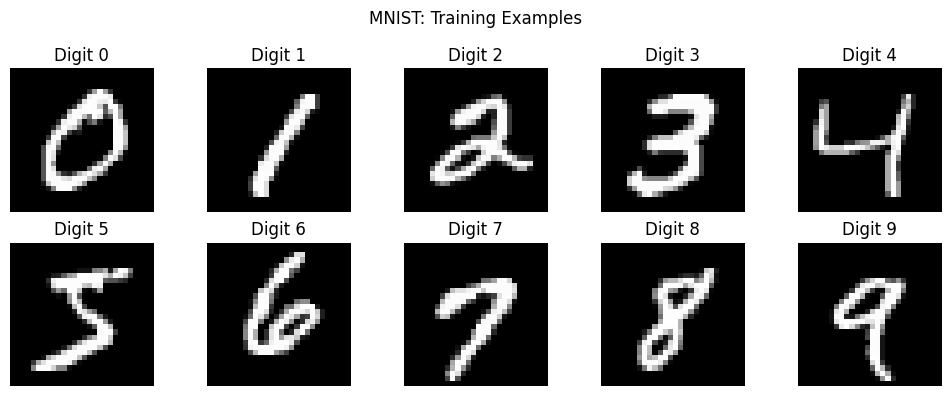

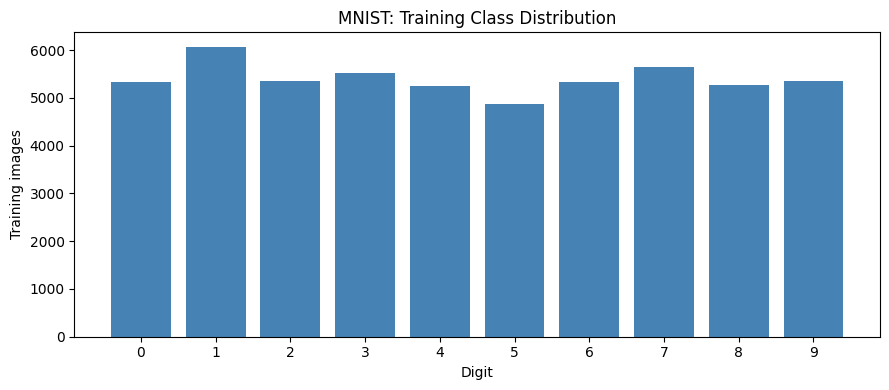

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    index = train_indices[np.flatnonzero(official_train_labels[train_indices] == digit)[0]]
    ax.imshow(official_train_images[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Digit {digit}')
    ax.axis('off')
fig.suptitle('MNIST: Training Examples')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_examples.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(class_counts.index, class_counts['train'], color='steelblue')
ax.set(xticks=range(10), xlabel='Digit', ylabel='Training images', title='MNIST: Training Class Distribution')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_class_distribution.png', dpi=160, bbox_inches='tight')
plt.show()


## 4. Shared input and evaluation conventions


In [6]:
X_train = torch.from_numpy(official_train_images[train_indices]).unsqueeze(1).float().div(255)
y_train = torch.from_numpy(official_train_labels[train_indices].astype(np.int64))
X_validation = torch.from_numpy(official_train_images[validation_indices]).unsqueeze(1).float().div(255)
y_validation = torch.from_numpy(official_train_labels[validation_indices].astype(np.int64))
assert X_train.shape == (54000, 1, 28, 28)
assert X_validation.shape == (6000, 1, 28, 28)
assert y_train.dtype == torch.int64
assert torch.isfinite(X_train).all() and torch.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64,
                          shuffle=True, generator=loader_generator, num_workers=0,
                          worker_init_fn=seed_worker, pin_memory=True)
validation_loader = DataLoader(TensorDataset(X_validation, y_validation), batch_size=64,
                               shuffle=False, num_workers=0, pin_memory=True)

def classification_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, labels=np.arange(10), average='macro', zero_division=0)),
    }

def gpu_time():
    torch.cuda.synchronize(device)
    return time.perf_counter()

print('Training tensors:', X_train.shape, y_train.shape)
print('Validation tensors:', X_validation.shape, y_validation.shape)
print('Input dtype:', X_train.dtype, '| Target dtype:', y_train.dtype)
print('Batches per training epoch:', len(train_loader))
print('PASS: tensors and data loaders ready. No test predictions computed.')


Training tensors: torch.Size([54000, 1, 28, 28]) torch.Size([54000])
Validation tensors: torch.Size([6000, 1, 28, 28]) torch.Size([6000])
Input dtype: torch.float32 | Target dtype: torch.int64
Batches per training epoch: 844
PASS: tensors and data loaders ready. No test predictions computed.


### Faster R-CNN adaptation and setup export


In [7]:
setup_config = {
    'dataset': 'hojjatk/mnist-dataset',
    'seed': SEED,
    'source_sha256': source_hashes,
    'split_sha256': split_hash,
    'partition_sizes': {name: len(labels) for name, labels in split_labels.items()},
    'split_policy': 'Stratified holdout from official train; official test kept separate',
    'cnn_vit_input': 'float32 grayscale pixels / 255; NCHW',
    'class_labels': list(range(10)),
    'metrics': ['accuracy', 'macro_f1', 'loss', 'training_seconds'],
    'selection_data': 'validation only',
    'timing': 'CUDA synchronized; includes per-epoch validation; excludes downloads',
    'faster_rcnn': {
        'box_policy': 'one derived full-image box per image',
        'background_label': 0,
        'digit_to_detector_label': 'digit + 1',
        'image_prediction': 'highest-scoring detection; no detection counts as incorrect',
        'score_threshold': 'to be fixed using validation in Issue 3',
        'loss_note': 'detection loss is not directly comparable to classifier cross-entropy',
    },
    'test_predictions_computed': False,
}
(RESULTS_DIR / 'mnist_setup_config.json').write_text(json.dumps(setup_config, indent=2))
print('Saved setup configuration:', RESULTS_DIR / 'mnist_setup_config.json')
print('PASS: Issue 1 setup cells completed. Review outputs before closing the issue.')


Saved setup configuration: /kaggle/working/results/mnist_setup_config.json
PASS: Issue 1 setup cells completed. Review outputs before closing the issue.


## 5. Model experiment


In [8]:
expected_split_hash = (
    "d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4"
)
assert split_hash == expected_split_hash
assert X_train.shape == (54000, 1, 28, 28)
assert X_validation.shape == (6000, 1, 28, 28)

vit_config = {
    "seed": SEED,
    "architecture": "Tutorial ViT from scratch",
    "tutorial_author": "Brian Pulfer",
    "pretrained": False,
    "input_shape": [1, 28, 28],
    "patches_per_side": 7,
    "patch_size": 4,
    "num_patches": 49,
    "sequence_length": 50,
    "hidden_dim": 8,
    "num_heads": 2,
    "head_dim": 4,
    "num_blocks": 2,
    "mlp_ratio": 4,
    "positional_encoding": "fixed sinusoidal",
    "attention": "tutorial per-head Q/K/V mappings",
    "num_classes": 10,
    "output": "logits",
    "optimizer": "Adam",
    "learning_rate": 0.005,
    "global_batch_size": 128,
    "max_epochs": 5,
    "loss": "CrossEntropyLoss",
    "checkpoint_selection": "lowest validation cross-entropy",
    "checkpoint_tie_break": "earliest epoch",
    "split_sha256": split_hash,
}

assert vit_config["hidden_dim"] % vit_config["num_heads"] == 0
assert vit_config["patch_size"] * vit_config["patches_per_side"] == 28

print(json.dumps(vit_config, indent=2))
print("Patch sequence: (batch, 49, 16)")
print("Embedded sequence with class token: (batch, 50, 8)")
print("Classifier output: (batch, 10) logits")
print("PASS: tutorial architecture and shared evaluation protocol defined.")
print("No training or test evaluation performed.")

{
  "seed": 42,
  "architecture": "Tutorial ViT from scratch",
  "tutorial_author": "Brian Pulfer",
  "pretrained": false,
  "input_shape": [
    1,
    28,
    28
  ],
  "patches_per_side": 7,
  "patch_size": 4,
  "num_patches": 49,
  "sequence_length": 50,
  "hidden_dim": 8,
  "num_heads": 2,
  "head_dim": 4,
  "num_blocks": 2,
  "mlp_ratio": 4,
  "positional_encoding": "fixed sinusoidal",
  "attention": "tutorial per-head Q/K/V mappings",
  "num_classes": 10,
  "output": "logits",
  "optimizer": "Adam",
  "learning_rate": 0.005,
  "global_batch_size": 128,
  "max_epochs": 5,
  "loss": "CrossEntropyLoss",
  "checkpoint_selection": "lowest validation cross-entropy",
  "checkpoint_tie_break": "earliest epoch",
  "split_sha256": "d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4"
}
Patch sequence: (batch, 49, 16)
Embedded sequence with class token: (batch, 50, 8)
Classifier output: (batch, 10) logits
PASS: tutorial architecture and shared evaluation protocol defined.
No t

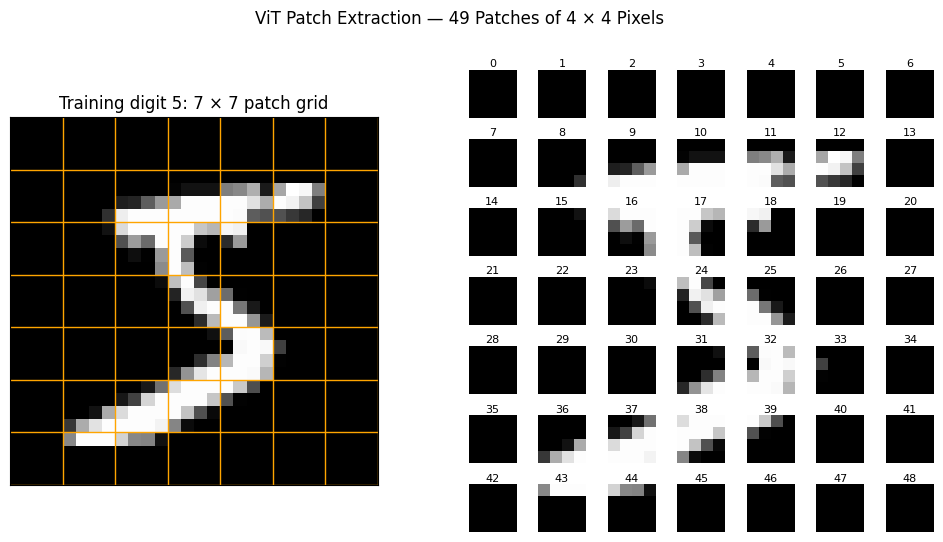

Patch tensor shape: (8, 49, 16)
Device: cuda:0
PASS: vectorized patches exactly match the tutorial's loop order.
PASS: reconstructing the patches recovers the original images.
No training or test evaluation performed.


In [9]:
def patchify(images, n_patches):
    assert images.ndim == 4
    batch_size, channels, height, width = images.shape
    assert height == width
    assert n_patches > 0
    assert height % n_patches == 0
    assert width % n_patches == 0

    patch_height = height // n_patches
    patch_width = width // n_patches

    return (
        images.reshape(
            batch_size,
            channels,
            n_patches,
            patch_height,
            n_patches,
            patch_width,
        )
        .permute(0, 2, 4, 1, 3, 5)
        .reshape(
            batch_size,
            n_patches**2,
            channels * patch_height * patch_width,
        )
    )


vit_sample_images = X_train[:8].to(device)
vit_sample_patches = patchify(
    vit_sample_images,
    vit_config["patches_per_side"],
)

reference_patches = torch.stack([
    torch.stack([
        image[:, row * 4:(row + 1) * 4, col * 4:(col + 1) * 4].flatten()
        for row in range(7)
        for col in range(7)
    ])
    for image in vit_sample_images
])

assert vit_sample_patches.shape == (8, 49, 16)
assert vit_sample_patches.device == vit_sample_images.device
assert vit_sample_patches.dtype == vit_sample_images.dtype
assert torch.equal(vit_sample_patches, reference_patches)

reconstructed_images = (
    vit_sample_patches.reshape(8, 7, 7, 1, 4, 4)
    .permute(0, 3, 1, 4, 2, 5)
    .reshape(8, 1, 28, 28)
)
assert torch.equal(reconstructed_images, vit_sample_images)

fig = plt.figure(figsize=(12, 6))
layout = fig.add_gridspec(1, 2, width_ratios=[1, 1.3])

image_ax = fig.add_subplot(layout[0, 0])
image_ax.imshow(vit_sample_images[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)
image_ax.set_title(f"Training digit {int(y_train[0])}: 7 × 7 patch grid")
image_ax.set_xticks(np.arange(3.5, 28, 4), minor=True)
image_ax.set_yticks(np.arange(3.5, 28, 4), minor=True)
image_ax.grid(which="minor", color="orange", linewidth=1)
image_ax.tick_params(which="both", bottom=False, left=False)
image_ax.set_xticks([])
image_ax.set_yticks([])

patch_layout = layout[0, 1].subgridspec(7, 7, wspace=0.15, hspace=0.45)
for index in range(49):
    ax = fig.add_subplot(patch_layout[index // 7, index % 7])
    ax.imshow(
        vit_sample_patches[0, index].reshape(4, 4).cpu(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(str(index), fontsize=8, pad=2)
    ax.axis("off")

fig.suptitle("ViT Patch Extraction — 49 Patches of 4 × 4 Pixels")
fig.savefig(
    PLOTS_DIR / "vit_patch_extraction.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Patch tensor shape:", tuple(vit_sample_patches.shape))
print("Device:", vit_sample_patches.device)
print("PASS: vectorized patches exactly match the tutorial's loop order.")
print("PASS: reconstructing the patches recovers the original images.")
print("No training or test evaluation performed.")

In [10]:
class PatchEmbedding(nn.Module):
    def __init__(self, chw=(1, 28, 28), n_patches=7, hidden_d=8):
        super().__init__()
        self.chw = tuple(chw)
        self.n_patches = n_patches

        channels, height, width = self.chw
        assert height % n_patches == 0
        assert width % n_patches == 0

        patch_dim = (
            channels * (height // n_patches) * (width // n_patches)
        )
        self.linear_mapper = nn.Linear(patch_dim, hidden_d)
        self.class_token = nn.Parameter(torch.rand(1, hidden_d))

    def forward(self, images):
        assert tuple(images.shape[1:]) == self.chw
        patches = patchify(images, self.n_patches)
        tokens = self.linear_mapper(patches)
        class_tokens = self.class_token.expand(images.size(0), 1, -1)
        return torch.cat((class_tokens, tokens), dim=1)


with torch.random.fork_rng(devices=[device.index]):
    torch.manual_seed(SEED)
    vit_embedding_demo = PatchEmbedding(
        chw=vit_config["input_shape"],
        n_patches=vit_config["patches_per_side"],
        hidden_d=vit_config["hidden_dim"],
    ).to(device)

with torch.no_grad():
    vit_sample_tokens = vit_embedding_demo(vit_sample_images)
    mapped_patches = vit_embedding_demo.linear_mapper(vit_sample_patches)

assert vit_sample_tokens.shape == (8, 50, 8)
assert torch.isfinite(vit_sample_tokens).all()
assert torch.equal(vit_sample_tokens[:, 1:], mapped_patches)
assert torch.equal(
    vit_sample_tokens[:, 0],
    vit_embedding_demo.class_token.expand(8, -1),
)

print(vit_embedding_demo)
print("Input patches:", tuple(vit_sample_patches.shape))
print("Tokens including classification token:", tuple(vit_sample_tokens.shape))
print("Classification token requires gradients:",
      vit_embedding_demo.class_token.requires_grad)
print(
    "Embedding parameters:",
    sum(p.numel() for p in vit_embedding_demo.parameters()),
)
print("PASS: linear patch mapping and shared learnable class token.")
print("No training or test evaluation performed.")

PatchEmbedding(
  (linear_mapper): Linear(in_features=16, out_features=8, bias=True)
)
Input patches: (8, 49, 16)
Tokens including classification token: (8, 50, 8)
Classification token requires gradients: True
Embedding parameters: 144
PASS: linear patch mapping and shared learnable class token.
No training or test evaluation performed.


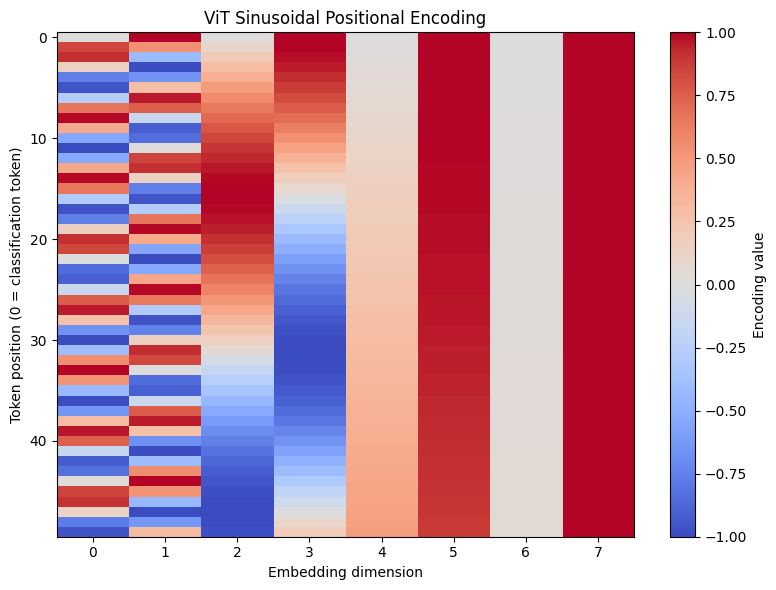

Positional encoding shape: (50, 8)
First position: [0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0]
Tokens after adding positions: (8, 50, 8)
PASS: positional encoding matches the tutorial formula.
No training or test evaluation performed.


In [11]:
def get_positional_embeddings(sequence_length, d):
    assert sequence_length > 0
    assert d > 0 and d % 2 == 0

    positions = torch.arange(
        sequence_length, dtype=torch.float64
    ).unsqueeze(1)
    dimensions = torch.arange(0, d, 2, dtype=torch.float64)
    angles = positions / (10000 ** (dimensions / d))

    embeddings = torch.empty(sequence_length, d, dtype=torch.float64)
    embeddings[:, 0::2] = torch.sin(angles)
    embeddings[:, 1::2] = torch.cos(angles)
    return embeddings.float()


vit_position_embeddings = get_positional_embeddings(
    vit_config["sequence_length"],
    vit_config["hidden_dim"],
)

reference_positions = torch.tensor([
    [
        np.sin(position / (10000 ** (dimension / vit_config["hidden_dim"])))
        if dimension % 2 == 0
        else np.cos(
            position / (10000 ** ((dimension - 1) / vit_config["hidden_dim"]))
        )
        for dimension in range(vit_config["hidden_dim"])
    ]
    for position in range(vit_config["sequence_length"])
], dtype=torch.float32)

assert torch.allclose(
    vit_position_embeddings,
    reference_positions,
    atol=1e-7,
    rtol=1e-6,
)
assert not vit_position_embeddings.requires_grad
assert torch.unique(vit_position_embeddings, dim=0).shape[0] == 50

vit_positioned_tokens = (
    vit_sample_tokens
    + vit_position_embeddings.to(device).unsqueeze(0)
)

assert vit_positioned_tokens.shape == (8, 50, 8)
assert torch.isfinite(vit_positioned_tokens).all()

fig, ax = plt.subplots(figsize=(8, 6))
heatmap = ax.imshow(
    vit_position_embeddings.numpy(),
    aspect="auto",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
ax.set_title("ViT Sinusoidal Positional Encoding")
ax.set_xlabel("Embedding dimension")
ax.set_ylabel("Token position (0 = classification token)")
ax.set_xticks(np.arange(vit_config["hidden_dim"]))
fig.colorbar(heatmap, ax=ax, label="Encoding value")
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "vit_positional_encoding.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Positional encoding shape:", tuple(vit_position_embeddings.shape))
print("First position:", vit_position_embeddings[0].tolist())
print("Tokens after adding positions:", tuple(vit_positioned_tokens.shape))
print("PASS: positional encoding matches the tutorial formula.")
print("No training or test evaluation performed.")

In [12]:
class MyMSA(nn.Module):
    def __init__(self, d, n_heads=2):
        super().__init__()
        assert d % n_heads == 0

        self.d = d
        self.n_heads = n_heads
        self.d_head = d // n_heads

        self.q_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head)
            for _ in range(n_heads)
        ])
        self.k_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head)
            for _ in range(n_heads)
        ])
        self.v_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head)
            for _ in range(n_heads)
        ])

    def forward(self, sequences, return_attention=False):
        assert sequences.ndim == 3
        assert sequences.shape[-1] == self.d

        head_outputs = []
        attention_maps = []

        for head in range(self.n_heads):
            start = head * self.d_head
            sequence = sequences[:, :, start:start + self.d_head]

            q = self.q_mappings[head](sequence)
            k = self.k_mappings[head](sequence)
            v = self.v_mappings[head](sequence)

            scores = q @ k.transpose(-2, -1) / (self.d_head ** 0.5)
            attention = torch.softmax(scores, dim=-1)
            head_outputs.append(attention @ v)

            if return_attention:
                attention_maps.append(attention)

        output = torch.cat(head_outputs, dim=-1)

        if return_attention:
            return output, torch.stack(attention_maps, dim=1)
        return output


with torch.random.fork_rng(devices=[device.index]):
    torch.manual_seed(SEED)
    vit_attention_demo = MyMSA(
        d=vit_config["hidden_dim"],
        n_heads=vit_config["num_heads"],
    ).to(device)

with torch.no_grad():
    vit_attention_output, vit_attention_maps = vit_attention_demo(
        vit_positioned_tokens,
        return_attention=True,
    )

    reference_outputs = []
    for sequence in vit_positioned_tokens:
        head_outputs = []
        for head in range(vit_attention_demo.n_heads):
            start = head * vit_attention_demo.d_head
            head_sequence = sequence[
                :, start:start + vit_attention_demo.d_head
            ]

            q = vit_attention_demo.q_mappings[head](head_sequence)
            k = vit_attention_demo.k_mappings[head](head_sequence)
            v = vit_attention_demo.v_mappings[head](head_sequence)

            attention = torch.softmax(
                q @ k.T / (vit_attention_demo.d_head ** 0.5),
                dim=-1,
            )
            head_outputs.append(attention @ v)

        reference_outputs.append(torch.cat(head_outputs, dim=-1))

    reference_attention_output = torch.stack(reference_outputs)

assert vit_attention_output.shape == (8, 50, 8)
assert vit_attention_maps.shape == (8, 2, 50, 50)
assert torch.isfinite(vit_attention_output).all()
assert torch.allclose(
    vit_attention_output,
    reference_attention_output,
    atol=1e-6,
    rtol=1e-5,
)
assert torch.allclose(
    vit_attention_maps.sum(dim=-1),
    torch.ones_like(vit_attention_maps.sum(dim=-1)),
    atol=1e-6,
    rtol=1e-5,
)

print("Attention output shape:", tuple(vit_attention_output.shape))
print("Attention maps: (batch, heads, query tokens, key tokens)")
print("Attention map shape:", tuple(vit_attention_maps.shape))
print(
    "Attention parameters:",
    sum(p.numel() for p in vit_attention_demo.parameters()),
)
print("PASS: batched attention matches the tutorial's loop implementation.")
print("PASS: attention weights sum to one for each query token.")
print("No training or test evaluation performed.")

Attention output shape: (8, 50, 8)
Attention maps: (batch, heads, query tokens, key tokens)
Attention map shape: (8, 2, 50, 50)
Attention parameters: 120
PASS: batched attention matches the tutorial's loop implementation.
PASS: attention weights sum to one for each query token.
No training or test evaluation performed.


In [13]:
class MyViTBlock(nn.Module):
    def __init__(self, hidden_d, n_heads, mlp_ratio=4):
        super().__init__()

        self.norm1 = nn.LayerNorm(hidden_d)
        self.mhsa = MyMSA(hidden_d, n_heads)
        self.norm2 = nn.LayerNorm(hidden_d)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_d, mlp_ratio * hidden_d),
            nn.GELU(),
            nn.Linear(mlp_ratio * hidden_d, hidden_d),
        )

    def forward(self, x):
        out = x + self.mhsa(self.norm1(x))
        return out + self.mlp(self.norm2(out))


with torch.random.fork_rng(devices=[device.index]):
    torch.manual_seed(SEED)
    vit_block_demo = MyViTBlock(
        hidden_d=vit_config["hidden_dim"],
        n_heads=vit_config["num_heads"],
        mlp_ratio=vit_config["mlp_ratio"],
    ).to(device)

vit_block_input = vit_positioned_tokens.detach().clone().requires_grad_(True)
vit_block_output = vit_block_demo(vit_block_input)

assert vit_block_output.shape == (8, 50, 8)
assert torch.isfinite(vit_block_output).all()

with torch.no_grad():
    first_residual = vit_block_input + vit_block_demo.mhsa(
        vit_block_demo.norm1(vit_block_input)
    )
    reference_block_output = first_residual + vit_block_demo.mlp(
        vit_block_demo.norm2(first_residual)
    )

assert torch.allclose(
    vit_block_output,
    reference_block_output,
    atol=1e-6,
    rtol=1e-5,
)

vit_block_output.square().mean().backward()

assert vit_block_input.grad is not None
assert torch.isfinite(vit_block_input.grad).all()
for name, parameter in vit_block_demo.named_parameters():
    assert parameter.grad is not None, f"Missing gradient: {name}"
    assert torch.isfinite(parameter.grad).all(), f"Non-finite gradient: {name}"

vit_block_demo.zero_grad(set_to_none=True)

print(vit_block_demo)
print("Block output shape:", tuple(vit_block_output.shape))
print(
    "Block parameters:",
    sum(p.numel() for p in vit_block_demo.parameters()),
)
print("PASS: both residual connections match the tutorial.")
print("PASS: finite gradients reach the input and all block parameters.")
print("No optimizer updates or test evaluation performed.")

MyViTBlock(
  (norm1): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (mhsa): MyMSA(
    (q_mappings): ModuleList(
      (0-1): 2 x Linear(in_features=4, out_features=4, bias=True)
    )
    (k_mappings): ModuleList(
      (0-1): 2 x Linear(in_features=4, out_features=4, bias=True)
    )
    (v_mappings): ModuleList(
      (0-1): 2 x Linear(in_features=4, out_features=4, bias=True)
    )
  )
  (norm2): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
  (mlp): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=32, out_features=8, bias=True)
  )
)
Block output shape: (8, 50, 8)
Block parameters: 704
PASS: both residual connections match the tutorial.
PASS: finite gradients reach the input and all block parameters.
No optimizer updates or test evaluation performed.


In [14]:
class MyViT(nn.Module):
    def __init__(
        self,
        chw=(1, 28, 28),
        n_patches=7,
        n_blocks=2,
        hidden_d=8,
        n_heads=2,
        mlp_ratio=4,
        out_d=10,
    ):
        super().__init__()

        self.embedding = PatchEmbedding(chw, n_patches, hidden_d)
        self.register_buffer(
            "positional_embeddings",
            get_positional_embeddings(n_patches**2 + 1, hidden_d),
        )
        self.blocks = nn.ModuleList([
            MyViTBlock(hidden_d, n_heads, mlp_ratio)
            for _ in range(n_blocks)
        ])
        self.classifier = nn.Linear(hidden_d, out_d)

    def forward(self, images):
        tokens = self.embedding(images)
        tokens = tokens + self.positional_embeddings.unsqueeze(0)

        for block in self.blocks:
            tokens = block(tokens)

        return self.classifier(tokens[:, 0])


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

vit_model = MyViT(
    chw=vit_config["input_shape"],
    n_patches=vit_config["patches_per_side"],
    n_blocks=vit_config["num_blocks"],
    hidden_d=vit_config["hidden_dim"],
    n_heads=vit_config["num_heads"],
    mlp_ratio=vit_config["mlp_ratio"],
    out_d=vit_config["num_classes"],
).to(device)

vit_criterion = nn.CrossEntropyLoss()
vit_model.train()

vit_sample_logits = vit_model(X_train[:8].to(device))
vit_sample_loss = vit_criterion(
    vit_sample_logits,
    y_train[:8].to(device),
)

assert vit_sample_logits.shape == (8, 10)
assert torch.isfinite(vit_sample_logits).all()
assert torch.isfinite(vit_sample_loss)

vit_sample_loss.backward()

for name, parameter in vit_model.named_parameters():
    assert parameter.grad is not None, f"Missing gradient: {name}"
    assert torch.isfinite(parameter.grad).all(), f"Non-finite gradient: {name}"

assert not vit_model.positional_embeddings.requires_grad
assert vit_model.positional_embeddings.grad is None

vit_model.zero_grad(set_to_none=True)

vit_parameter_count = sum(
    p.numel() for p in vit_model.parameters() if p.requires_grad
)
assert vit_parameter_count == 1642
vit_config["trainable_parameters"] = vit_parameter_count

print(vit_model)
print("Trainable parameters:", vit_parameter_count)
print("Positional encoding shape:",
      tuple(vit_model.positional_embeddings.shape))
print("Output shape:", tuple(vit_sample_logits.shape))
print("Device:", next(vit_model.parameters()).device)
print("PASS: complete ViT produces finite logits, loss, and gradients.")
print("No optimizer updates or test evaluation performed.")

MyViT(
  (embedding): PatchEmbedding(
    (linear_mapper): Linear(in_features=16, out_features=8, bias=True)
  )
  (blocks): ModuleList(
    (0-1): 2 x MyViTBlock(
      (norm1): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
      (mhsa): MyMSA(
        (q_mappings): ModuleList(
          (0-1): 2 x Linear(in_features=4, out_features=4, bias=True)
        )
        (k_mappings): ModuleList(
          (0-1): 2 x Linear(in_features=4, out_features=4, bias=True)
        )
        (v_mappings): ModuleList(
          (0-1): 2 x Linear(in_features=4, out_features=4, bias=True)
        )
      )
      (norm2): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
      (mlp): Sequential(
        (0): Linear(in_features=8, out_features=32, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=32, out_features=8, bias=True)
      )
    )
  )
  (classifier): Linear(in_features=8, out_features=10, bias=True)
)
Trainable parameters: 1642
Positional encoding shape: (5

In [15]:
vit_train_dataset = TensorDataset(X_train, y_train)
vit_validation_dataset = TensorDataset(X_validation, y_validation)

vit_loader_generator = torch.Generator().manual_seed(SEED)

vit_train_loader = DataLoader(
    vit_train_dataset,
    batch_size=vit_config["global_batch_size"],
    shuffle=True,
    generator=vit_loader_generator,
    num_workers=0,
    pin_memory=True,
)

vit_train_eval_loader = DataLoader(
    vit_train_dataset,
    batch_size=vit_config["global_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

vit_validation_loader = DataLoader(
    vit_validation_dataset,
    batch_size=vit_config["global_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

assert X_train.dtype == X_validation.dtype == torch.float32
assert y_train.dtype == y_validation.dtype == torch.int64
assert X_train.min().item() >= 0 and X_train.max().item() <= 1
assert X_validation.min().item() >= 0 and X_validation.max().item() <= 1

print("Training images:", len(vit_train_dataset))
print("Validation images:", len(vit_validation_dataset))
print("Global batch size:", vit_config["global_batch_size"])
print("Training batches per epoch:", len(vit_train_loader))
print("Validation batches:", len(vit_validation_loader))
print("Input shape:", tuple(X_train.shape[1:]))
print("Visible GPUs:", torch.cuda.device_count())
print("PASS: ViT data loaders ready.")
print("No optimizer updates or test evaluation performed.")

Training images: 54000
Validation images: 6000
Global batch size: 128
Training batches per epoch: 422
Validation batches: 47
Input shape: (1, 28, 28)
Visible GPUs: 2
PASS: ViT data loaders ready.
No optimizer updates or test evaluation performed.


In [16]:
def evaluate_vit(model, loader):
    previous_mode = model.training
    model.eval()
    model_device = next(model.parameters()).device

    loss_sum = torch.zeros((), dtype=torch.float64, device=model_device)
    sample_count = 0
    collected_labels = []
    collected_predictions = []

    try:
        with torch.inference_mode():
            for images, labels in loader:
                images = images.to(model_device, non_blocking=True)
                labels = labels.to(model_device, non_blocking=True)

                logits = model(images)
                batch_loss = nn.functional.cross_entropy(
                    logits, labels, reduction="sum"
                )

                if not torch.isfinite(batch_loss):
                    raise RuntimeError("Non-finite ViT evaluation loss.")

                loss_sum += batch_loss.double()
                sample_count += labels.size(0)
                collected_labels.append(labels.cpu())
                collected_predictions.append(logits.argmax(dim=1).cpu())
    finally:
        model.train(previous_mode)

    if sample_count == 0:
        raise ValueError("The evaluation loader contains no samples.")

    true_labels = torch.cat(collected_labels).numpy()
    predictions = torch.cat(collected_predictions).numpy()

    metrics = {
        "loss": loss_sum.item() / sample_count,
        "accuracy": accuracy_score(true_labels, predictions),
        "macro_f1": f1_score(
            true_labels,
            predictions,
            labels=np.arange(10),
            average="macro",
            zero_division=0,
        ),
    }

    return metrics, true_labels, predictions


print("Evaluation function ready.")
print("Loss: sample-weighted mean cross-entropy.")
print("Metrics: accuracy and macro-F1 across all ten digits.")
print("Training evaluation uses all original 54,000 training images.")
print("No optimizer updates or test evaluation performed.")

Evaluation function ready.
Loss: sample-weighted mean cross-entropy.
Metrics: accuracy and macro-F1 across all ten digits.
Training evaluation uses all original 54,000 training images.
No optimizer updates or test evaluation performed.


In [17]:
vit_worker_dir = Path("/kaggle/working/vit_ddp")
vit_worker_dir.mkdir(parents=True, exist_ok=True)

assert torch.cuda.device_count() >= 2, "Enable two GPUs in Kaggle."
assert torch.distributed.is_available()
assert torch.distributed.is_nccl_available()

vit_ddp_config = {
    **vit_config,
    "world_size": 2,
    "gpus_used": 2,
    "batch_size_per_gpu": 64,
    "precision": "float32",
    "training_evaluation": "all original training images",
    "timing_scope": (
        "training, per-epoch training and validation evaluation, "
        "and checkpoint writes; excludes worker startup and input loading"
    ),
    "tutorial_adaptations": [
        "Shared 54,000/6,000 training-validation split and seed 42.",
        "Vectorized patch extraction and batched per-head attention.",
        "Final classifier returns logits for CrossEntropyLoss.",
        "Fixed positional encoding stored in the checkpoint as a buffer.",
        "Checkpoint selected by lowest validation cross-entropy.",
        "Two-GPU training with unchanged global batch size of 128.",
    ],
}

assert (
    vit_ddp_config["batch_size_per_gpu"]
    * vit_ddp_config["world_size"]
    == vit_ddp_config["global_batch_size"]
)
assert len(X_train) == len(y_train) == 54000
assert len(X_validation) == len(y_validation) == 6000

vit_worker_arrays = {
    "train_images": X_train.detach().cpu().numpy(),
    "train_labels": y_train.detach().cpu().numpy(),
    "validation_images": X_validation.detach().cpu().numpy(),
    "validation_labels": y_validation.detach().cpu().numpy(),
}

for name, array in vit_worker_arrays.items():
    np.save(vit_worker_dir / f"{name}.npy", array, allow_pickle=False)

vit_model = vit_model.cpu()
vit_initial_weights_path = vit_worker_dir / "initial_weights.pt"
torch.save(vit_model.state_dict(), vit_initial_weights_path)

(vit_worker_dir / "config.json").write_text(
    json.dumps(vit_ddp_config, indent=2),
    encoding="utf-8",
)

assert vit_initial_weights_path.is_file()
assert sum(p.numel() for p in vit_model.parameters()) == 1642

torch.cuda.empty_cache()

print("Worker input directory:", vit_worker_dir)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))
print("GPUs:", vit_ddp_config["world_size"])
print("Global batch size:", vit_ddp_config["global_batch_size"])
print("Batch size per GPU:", vit_ddp_config["batch_size_per_gpu"])
print("Training epochs:", vit_ddp_config["max_epochs"])
print("Notebook model device:", next(vit_model.parameters()).device)
print("Split SHA256:", vit_ddp_config["split_sha256"])
print("PASS: worker inputs and initial weights saved.")
print("No training performed; no test data exported.")

Worker input directory: /kaggle/working/vit_ddp
Training samples: 54000
Validation samples: 6000
GPUs: 2
Global batch size: 128
Batch size per GPU: 64
Training epochs: 5
Notebook model device: cpu
Split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: worker inputs and initial weights saved.
No training performed; no test data exported.


In [18]:
%%writefile /kaggle/working/vit_ddp/worker.py
import csv
import json
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.distributed as dist
from torch import nn
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, DistributedSampler, Subset, TensorDataset


def patchify(images, n_patches):
    n, c, h, w = images.shape
    assert h == w and h % n_patches == 0
    ph, pw = h // n_patches, w // n_patches
    return (
        images.reshape(n, c, n_patches, ph, n_patches, pw)
        .permute(0, 2, 4, 1, 3, 5)
        .reshape(n, n_patches**2, c * ph * pw)
    )


def get_positional_embeddings(sequence_length, d):
    assert d > 0 and d % 2 == 0
    positions = torch.arange(sequence_length, dtype=torch.float64).unsqueeze(1)
    dimensions = torch.arange(0, d, 2, dtype=torch.float64)
    angles = positions / (10000 ** (dimensions / d))
    embeddings = torch.empty(sequence_length, d, dtype=torch.float64)
    embeddings[:, 0::2] = torch.sin(angles)
    embeddings[:, 1::2] = torch.cos(angles)
    return embeddings.float()


class PatchEmbedding(nn.Module):
    def __init__(self, chw=(1, 28, 28), n_patches=7, hidden_d=8):
        super().__init__()
        self.chw = tuple(chw)
        self.n_patches = n_patches
        c, h, w = self.chw
        assert h % n_patches == 0 and w % n_patches == 0
        patch_dim = c * (h // n_patches) * (w // n_patches)
        self.linear_mapper = nn.Linear(patch_dim, hidden_d)
        self.class_token = nn.Parameter(torch.rand(1, hidden_d))

    def forward(self, images):
        assert tuple(images.shape[1:]) == self.chw
        tokens = self.linear_mapper(patchify(images, self.n_patches))
        class_tokens = self.class_token.expand(images.size(0), 1, -1)
        return torch.cat((class_tokens, tokens), dim=1)


class MyMSA(nn.Module):
    def __init__(self, d, n_heads=2):
        super().__init__()
        assert d % n_heads == 0
        self.d = d
        self.n_heads = n_heads
        self.d_head = d // n_heads
        self.q_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)
        ])
        self.k_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)
        ])
        self.v_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)
        ])

    def forward(self, sequences, return_attention=False):
        assert sequences.ndim == 3 and sequences.shape[-1] == self.d
        head_outputs, attention_maps = [], []

        for head in range(self.n_heads):
            start = head * self.d_head
            sequence = sequences[:, :, start:start + self.d_head]
            q = self.q_mappings[head](sequence)
            k = self.k_mappings[head](sequence)
            v = self.v_mappings[head](sequence)
            scores = q @ k.transpose(-2, -1) / (self.d_head ** 0.5)
            attention = torch.softmax(scores, dim=-1)
            head_outputs.append(attention @ v)
            if return_attention:
                attention_maps.append(attention)

        output = torch.cat(head_outputs, dim=-1)
        if return_attention:
            return output, torch.stack(attention_maps, dim=1)
        return output


class MyViTBlock(nn.Module):
    def __init__(self, hidden_d, n_heads, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden_d)
        self.mhsa = MyMSA(hidden_d, n_heads)
        self.norm2 = nn.LayerNorm(hidden_d)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_d, mlp_ratio * hidden_d),
            nn.GELU(),
            nn.Linear(mlp_ratio * hidden_d, hidden_d),
        )

    def forward(self, x):
        out = x + self.mhsa(self.norm1(x))
        return out + self.mlp(self.norm2(out))


class MyViT(nn.Module):
    def __init__(
        self, chw=(1, 28, 28), n_patches=7, n_blocks=2,
        hidden_d=8, n_heads=2, mlp_ratio=4, out_d=10,
    ):
        super().__init__()
        self.embedding = PatchEmbedding(chw, n_patches, hidden_d)
        self.register_buffer(
            "positional_embeddings",
            get_positional_embeddings(n_patches**2 + 1, hidden_d),
        )
        self.blocks = nn.ModuleList([
            MyViTBlock(hidden_d, n_heads, mlp_ratio)
            for _ in range(n_blocks)
        ])
        self.classifier = nn.Linear(hidden_d, out_d)

    def forward(self, images):
        tokens = self.embedding(images)
        tokens = tokens + self.positional_embeddings.unsqueeze(0)
        for block in self.blocks:
            tokens = block(tokens)
        return self.classifier(tokens[:, 0])


def synchronize():
    torch.cuda.synchronize()
    dist.barrier()


def evaluate(model, loader, device, expected_samples):
    previous_mode = model.training
    model.eval()
    totals = torch.zeros(2, dtype=torch.float64, device=device)
    confusion = torch.zeros((10, 10), dtype=torch.int64, device=device)

    try:
        with torch.inference_mode():
            for images, labels in loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                logits = model(images)
                totals[0] += nn.functional.cross_entropy(
                    logits, labels, reduction="sum"
                ).double()
                totals[1] += labels.numel()
                predictions = logits.argmax(dim=1)
                confusion += torch.bincount(
                    labels * 10 + predictions, minlength=100
                ).reshape(10, 10)

        dist.all_reduce(totals)
        dist.all_reduce(confusion)
        assert int(totals[1].item()) == expected_samples
        assert int(confusion.sum().item()) == expected_samples
        assert torch.isfinite(totals[0])

        matrix = confusion.cpu().numpy().astype(np.float64)
        correct = np.diag(matrix)
        denominator = matrix.sum(axis=0) + matrix.sum(axis=1)
        f1 = np.divide(
            2 * correct, denominator,
            out=np.zeros(10), where=denominator > 0,
        )
        return {
            "loss": float((totals[0] / totals[1]).item()),
            "accuracy": float(correct.sum() / matrix.sum()),
            "macro_f1": float(f1.mean()),
        }
    finally:
        model.train(previous_mode)


def main():
    root = Path(__file__).resolve().parent
    config = json.loads((root / "config.json").read_text(encoding="utf-8"))
    local_rank = int(os.environ["LOCAL_RANK"])
    torch.cuda.set_device(local_rank)
    device = torch.device("cuda", local_rank)
    dist.init_process_group(backend="nccl", device_id=device)

    try:
        rank = dist.get_rank()
        world_size = dist.get_world_size()
        assert world_size == config["world_size"] == 2
        assert config["batch_size_per_gpu"] * world_size == 128

        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

        def load_dataset(prefix):
            images = torch.from_numpy(
                np.load(root / f"{prefix}_images.npy", allow_pickle=False)
            )
            labels = torch.from_numpy(
                np.load(root / f"{prefix}_labels.npy", allow_pickle=False)
            )
            assert images.dtype == torch.float32
            assert labels.dtype == torch.int64
            return TensorDataset(images, labels)

        train_dataset = load_dataset("train")
        validation_dataset = load_dataset("validation")
        assert len(train_dataset) == 54000
        assert len(validation_dataset) == 6000
        assert len(train_dataset) % world_size == 0

        model = MyViT(
            chw=config["input_shape"],
            n_patches=config["patches_per_side"],
            n_blocks=config["num_blocks"],
            hidden_d=config["hidden_dim"],
            n_heads=config["num_heads"],
            mlp_ratio=config["mlp_ratio"],
            out_d=config["num_classes"],
        )
        initial_state = torch.load(
            root / "initial_weights.pt",
            map_location="cpu",
            weights_only=True,
        )
        model.load_state_dict(initial_state, strict=True)
        del initial_state
        assert sum(p.numel() for p in model.parameters()) == 1642
        model = model.to(device)

        seed = config["seed"] + rank
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed(seed)

        sampler = DistributedSampler(
            train_dataset,
            num_replicas=world_size,
            rank=rank,
            shuffle=True,
            seed=config["seed"],
            drop_last=False,
        )
        loader_options = {
            "batch_size": config["batch_size_per_gpu"],
            "num_workers": 0,
            "pin_memory": True,
        }
        train_loader = DataLoader(
            train_dataset, sampler=sampler, **loader_options
        )
        train_eval_loader = DataLoader(
            Subset(train_dataset, range(rank, len(train_dataset), world_size)),
            shuffle=False, **loader_options,
        )
        validation_loader = DataLoader(
            Subset(
                validation_dataset,
                range(rank, len(validation_dataset), world_size),
            ),
            shuffle=False, **loader_options,
        )

        distributed_model = DDP(
            model, device_ids=[local_rank], broadcast_buffers=False
        )
        optimizer = torch.optim.Adam(
            model.parameters(), lr=config["learning_rate"], foreach=False
        )

        results_dir = Path("/kaggle/working/results")
        checkpoint_dir = Path("/kaggle/working/checkpoints")
        if rank == 0:
            results_dir.mkdir(parents=True, exist_ok=True)
            checkpoint_dir.mkdir(parents=True, exist_ok=True)
            print(
                f"GPUs: {world_size} | Global batch: 128 | "
                f"Parameters: 1642 | Epochs: {config['max_epochs']}",
                flush=True,
            )

        history = []
        best_loss = float("inf")
        best_epoch = None
        best_metrics = None

        synchronize()
        training_started = time.perf_counter()

        for epoch in range(1, config["max_epochs"] + 1):
            sampler.set_epoch(epoch - 1)
            synchronize()
            epoch_started = time.perf_counter()
            distributed_model.train()

            for images, labels in train_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                logits = distributed_model(images)
                loss = nn.functional.cross_entropy(logits, labels)
                if not torch.isfinite(loss):
                    raise RuntimeError(f"Non-finite loss at epoch {epoch}.")
                loss.backward()
                optimizer.step()

            optimizer.zero_grad(set_to_none=True)
            train_metrics = evaluate(
                model, train_eval_loader, device, 54000
            )
            validation_metrics = evaluate(
                model, validation_loader, device, 6000
            )

            if validation_metrics["loss"] < best_loss:
                best_loss = validation_metrics["loss"]
                best_epoch = epoch
                best_metrics = {
                    "train": train_metrics,
                    "validation": validation_metrics,
                }

                if rank == 0:
                    checkpoint_state = {
                        name: value.detach().cpu().clone()
                        for name, value in model.state_dict().items()
                    }
                    torch.save(
                        {
                            "model_state_dict": checkpoint_state,
                            "config": config,
                            "selected_epoch": best_epoch,
                            "metrics": best_metrics,
                            "split_sha256": config["split_sha256"],
                        },
                        checkpoint_dir / "vit_best.pt",
                    )

            synchronize()
            epoch_seconds = time.perf_counter() - epoch_started
            history.append({
                "epoch": epoch,
                **{f"train_{k}": v for k, v in train_metrics.items()},
                **{
                    f"validation_{k}": v
                    for k, v in validation_metrics.items()
                },
                "epoch_seconds": epoch_seconds,
            })

            if rank == 0:
                with (results_dir / "vit_training_history.csv").open(
                    "w", newline="", encoding="utf-8"
                ) as handle:
                    writer = csv.DictWriter(
                        handle, fieldnames=list(history[0])
                    )
                    writer.writeheader()
                    writer.writerows(history)

                print(
                    f"Epoch {epoch}/{config['max_epochs']} | "
                    f"Loss: {train_metrics['loss']:.4f} / "
                    f"{validation_metrics['loss']:.4f} | "
                    f"Accuracy: {train_metrics['accuracy']:.4f} / "
                    f"{validation_metrics['accuracy']:.4f} | "
                    f"Macro-F1: {train_metrics['macro_f1']:.4f} / "
                    f"{validation_metrics['macro_f1']:.4f} | "
                    f"Time: {epoch_seconds:.1f}s",
                    flush=True,
                )

        synchronize()
        training_seconds = time.perf_counter() - training_started

        if rank == 0:
            run_config = {
                **config,
                "selected_epoch": best_epoch,
                "selected_metrics": best_metrics,
                "training_seconds": training_seconds,
                "test_evaluated": False,
            }
            (results_dir / "vit_run_config.json").write_text(
                json.dumps(run_config, indent=2), encoding="utf-8"
            )
            print(
                f"\nTotal training time: {training_seconds / 60:.2f} minutes",
                flush=True,
            )
            print(f"Selected epoch: {best_epoch}", flush=True)
            print(
                "PASS: training finished; best validation-loss checkpoint saved.",
                flush=True,
            )
            print("Test set remains unevaluated.", flush=True)
    finally:
        dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing /kaggle/working/vit_ddp/worker.py


In [19]:
import os
import subprocess
import sys

vit_training_command = [
    sys.executable,
    "-m",
    "torch.distributed.run",
    "--standalone",
    "--nnodes=1",
    "--nproc_per_node=2",
    str(vit_worker_dir / "worker.py"),
]

vit_worker_environment = os.environ.copy()
vit_worker_environment["OMP_NUM_THREADS"] = "1"
vit_worker_environment["PYTHONUNBUFFERED"] = "1"

vit_training_log = vit_worker_dir / "training.log"

with vit_training_log.open("w", encoding="utf-8") as log:
    process = subprocess.Popen(
        vit_training_command,
        env=vit_worker_environment,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()

        return_code = process.wait()
    finally:
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=15)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        process.stdout.close()

if return_code != 0:
    raise RuntimeError(
        f"Distributed training failed. Inspect {vit_training_log}"
    )

vit_checkpoint_path = Path("/kaggle/working/checkpoints/vit_best.pt")
assert vit_checkpoint_path.is_file()

print("Saved checkpoint:", vit_checkpoint_path)
print(
    "Checkpoint size:",
    round(vit_checkpoint_path.stat().st_size / 1024, 2),
    "KiB",
)
print("PASS: distributed training completed and checkpoint exists.")

GPUs: 2 | Global batch: 128 | Parameters: 1642 | Epochs: 5
Epoch 1/5 | Loss: 1.0889 / 1.1009 | Accuracy: 0.6012 / 0.6075 | Macro-F1: 0.5960 / 0.6016 | Time: 7.2s
Epoch 2/5 | Loss: 0.8532 / 0.8695 | Accuracy: 0.6973 / 0.6945 | Macro-F1: 0.6865 / 0.6847 | Time: 7.2s
Epoch 3/5 | Loss: 0.5495 / 0.5655 | Accuracy: 0.8061 / 0.7998 | Macro-F1: 0.8018 / 0.7950 | Time: 7.3s
Epoch 4/5 | Loss: 0.5087 / 0.5158 | Accuracy: 0.8228 / 0.8227 | Macro-F1: 0.8164 / 0.8161 | Time: 7.0s
Epoch 5/5 | Loss: 0.5396 / 0.5392 | Accuracy: 0.8134 / 0.8175 | Macro-F1: 0.8138 / 0.8175 | Time: 7.0s

Total training time: 0.59 minutes
Selected epoch: 4
PASS: training finished; best validation-loss checkpoint saved.
Test set remains unevaluated.
Saved checkpoint: /kaggle/working/checkpoints/vit_best.pt
Checkpoint size: 23.39 KiB
PASS: distributed training completed and checkpoint exists.


In [20]:
vit_run_config = json.loads(
    (RESULTS_DIR / "vit_run_config.json").read_text(encoding="utf-8")
)
vit_history_df = pd.read_csv(
    RESULTS_DIR / "vit_training_history.csv"
)

vit_checkpoint = torch.load(
    Path("/kaggle/working/checkpoints/vit_best.pt"),
    map_location="cpu",
    weights_only=True,
)

assert vit_checkpoint["split_sha256"] == split_hash
assert vit_run_config["split_sha256"] == split_hash
assert vit_run_config["test_evaluated"] is False

vit_selected_epoch = int(vit_checkpoint["selected_epoch"])
assert vit_selected_epoch == vit_run_config["selected_epoch"]

selected_rows = vit_history_df.loc[
    vit_history_df["epoch"] == vit_selected_epoch
]
assert len(selected_rows) == 1
selected_row = selected_rows.iloc[0]

assert vit_selected_epoch == int(
    vit_history_df.loc[
        vit_history_df["validation_loss"].idxmin(), "epoch"
    ]
)

for split in ("train", "validation"):
    for metric in ("loss", "accuracy", "macro_f1"):
        saved_value = vit_checkpoint["metrics"][split][metric]
        assert np.isclose(
            saved_value,
            selected_row[f"{split}_{metric}"],
            rtol=1e-8,
            atol=1e-10,
        )
        assert np.isclose(
            saved_value,
            vit_run_config["selected_metrics"][split][metric],
            rtol=1e-8,
            atol=1e-10,
        )

vit_model.load_state_dict(vit_checkpoint["model_state_dict"], strict=True)
vit_model = vit_model.to(device)
vit_model.eval()

vit_selected_metrics = vit_checkpoint["metrics"]
del vit_checkpoint

vit_validation_metrics, vit_true_labels, vit_predictions = evaluate_vit(
    vit_model,
    vit_validation_loader,
)

assert len(vit_true_labels) == len(vit_predictions) == 6000
assert np.array_equal(vit_true_labels, y_validation.cpu().numpy())

for metric in ("accuracy", "macro_f1"):
    assert np.isclose(
        vit_validation_metrics[metric],
        vit_selected_metrics["validation"][metric],
        rtol=0,
        atol=1e-12,
    ), f"Restored predictions differ for {metric}."

assert np.isclose(
    vit_validation_metrics["loss"],
    vit_selected_metrics["validation"]["loss"],
    rtol=1e-4,
    atol=1e-6,
), "Restored validation loss differs beyond numerical tolerance."

vit_validation_predictions_df = pd.DataFrame({
    "source_index": validation_indices,
    "true_digit": vit_true_labels,
    "predicted_digit": vit_predictions,
    "correct": vit_true_labels == vit_predictions,
})
assert vit_validation_predictions_df["source_index"].is_unique

vit_validation_predictions_df.to_csv(
    RESULTS_DIR / "vit_validation_predictions.csv",
    index=False,
)

vit_metrics_df = pd.DataFrame([
    {"model": "ViT", "split": split, **metrics}
    for split, metrics in vit_selected_metrics.items()
])
vit_metrics_df.to_csv(RESULTS_DIR / "vit_metrics.csv", index=False)

display(vit_metrics_df)

print("Selected epoch:", vit_selected_epoch)
print("Verified validation metrics:", vit_validation_metrics)
print("Validation errors:", int((vit_true_labels != vit_predictions).sum()))
print("Saved validation predictions:", len(vit_validation_predictions_df))
print("PASS: restored predictions reproduce the selected checkpoint metrics.")
print("Test set remains unevaluated.")

,model,split,loss,accuracy,macro_f1
0,ViT,train,0.508706,0.822815,0.816423
1,ViT,validation,0.515797,0.822667,0.816108


Selected epoch: 4
Verified validation metrics: {'loss': 0.5157966143290201, 'accuracy': 0.8226666666666667, 'macro_f1': 0.8161077163448931}
Validation errors: 1064
Saved validation predictions: 6000
PASS: restored predictions reproduce the selected checkpoint metrics.
Test set remains unevaluated.


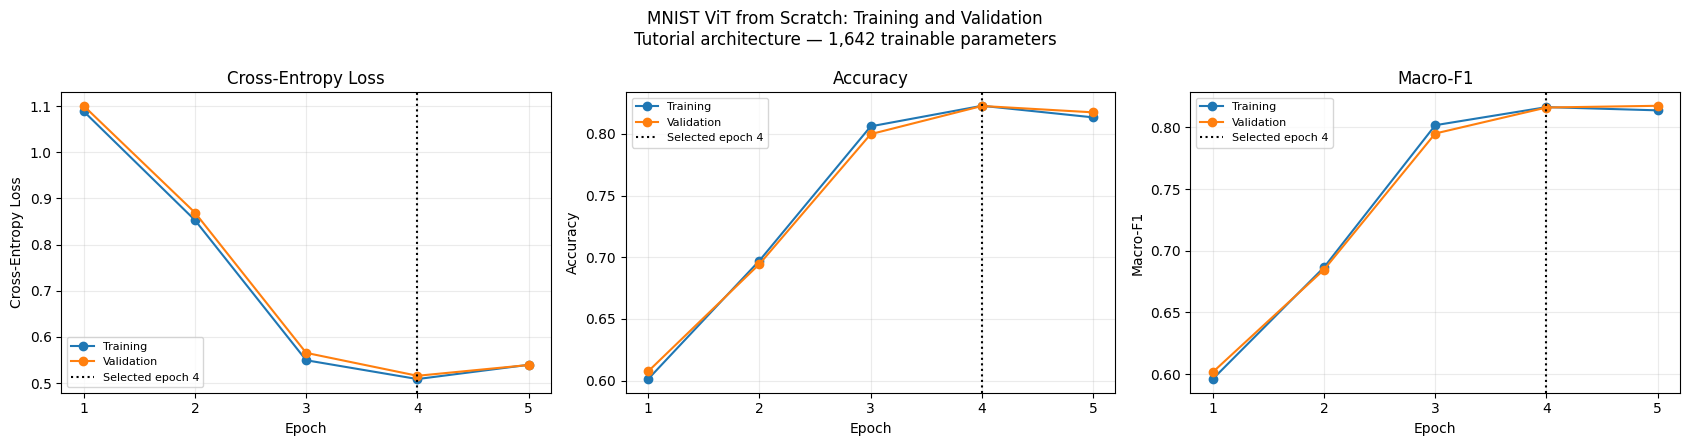

PASS: ViT learning curves saved.
Test set remains unevaluated.


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "macro_f1"],
    ["Cross-Entropy Loss", "Accuracy", "Macro-F1"],
):
    ax.plot(
        vit_history_df["epoch"],
        vit_history_df[f"train_{metric}"],
        marker="o",
        label="Training",
    )
    ax.plot(
        vit_history_df["epoch"],
        vit_history_df[f"validation_{metric}"],
        marker="o",
        label="Validation",
    )
    ax.axvline(
        vit_selected_epoch,
        color="black",
        linestyle=":",
        label=f"Selected epoch {vit_selected_epoch}",
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_xticks(vit_history_df["epoch"])
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "MNIST ViT from Scratch: Training and Validation\n"
    "Tutorial architecture — 1,642 trainable parameters"
)
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "vit_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("PASS: ViT learning curves saved.")
print("Test set remains unevaluated.")

,precision,recall,f1-score,support
digit_or_summary,,,,
0,0.9025,0.9223,0.9123,592.0000
1,0.9212,0.9718,0.9458,674.0000
2,0.8219,0.8674,0.8441,596.0000
3,0.8421,0.7308,0.7825,613.0000
4,0.6375,0.8613,0.7327,584.0000
5,0.7911,0.7196,0.7536,542.0000
6,0.7874,0.9324,0.8538,592.0000
7,0.9420,0.8804,0.9101,627.0000
8,0.8094,0.8274,0.8183,585.0000


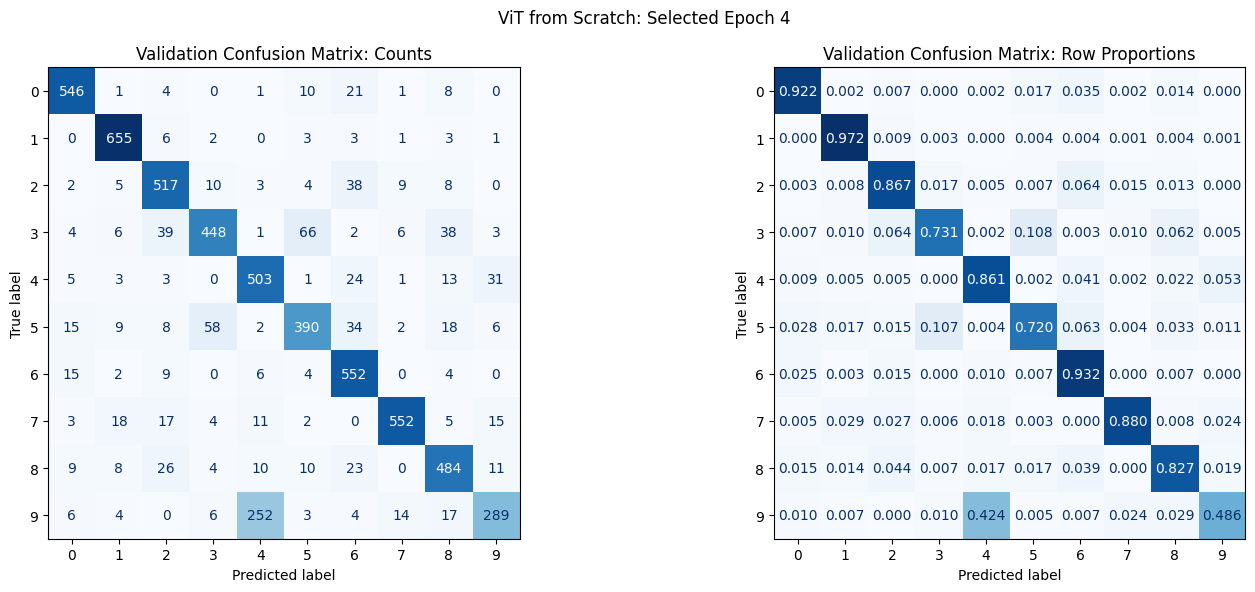

Validation errors: 1064
PASS: classification report matches the verified validation metrics.
Test set remains unevaluated.


In [22]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
)

vit_report = classification_report(
    vit_true_labels,
    vit_predictions,
    labels=np.arange(10),
    target_names=[str(digit) for digit in range(10)],
    output_dict=True,
    zero_division=0,
)
vit_report_df = pd.DataFrame(vit_report).T
vit_report_df.index.name = "digit_or_summary"

assert np.isclose(
    vit_report["accuracy"],
    vit_validation_metrics["accuracy"],
    atol=1e-12,
    rtol=0,
)
assert np.isclose(
    vit_report["macro avg"]["f1-score"],
    vit_validation_metrics["macro_f1"],
    atol=1e-12,
    rtol=0,
)

vit_report_df.to_csv(
    RESULTS_DIR / "vit_validation_classification_report.csv"
)
display(vit_report_df.round(4))

vit_counts = confusion_matrix(
    vit_true_labels,
    vit_predictions,
    labels=np.arange(10),
)
vit_proportions = vit_counts / vit_counts.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, matrix, title, value_format in [
    (axes[0], vit_counts, "Validation Confusion Matrix: Counts", "d"),
    (
        axes[1],
        vit_proportions,
        "Validation Confusion Matrix: Row Proportions",
        ".3f",
    ),
]:
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=np.arange(10),
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format=value_format,
        colorbar=False,
    )
    ax.set_title(title)

fig.suptitle(f"ViT from Scratch: Selected Epoch {vit_selected_epoch}")
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "vit_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Validation errors:", int((vit_true_labels != vit_predictions).sum()))
print("PASS: classification report matches the verified validation metrics.")
print("Test set remains unevaluated.")

In [23]:
import hashlib
import os
from zipfile import ZipFile, ZIP_STORED
from IPython.display import FileLink, display

vit_checkpoint_path = Path("/kaggle/working/checkpoints/vit_best.pt")
assert vit_checkpoint_path.is_file()

vit_digest = hashlib.sha256()
with vit_checkpoint_path.open("rb") as handle:
    for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
        vit_digest.update(chunk)

vit_checkpoint_sha256 = vit_digest.hexdigest()
vit_zip_path = Path("/kaggle/working/vit_checkpoint.zip")

with ZipFile(vit_zip_path, "w", compression=ZIP_STORED) as archive:
    archive.write(vit_checkpoint_path, arcname="vit_best.pt")
    archive.writestr(
        "SHA256.txt",
        f"{vit_checkpoint_sha256}  vit_best.pt\n",
    )

with ZipFile(vit_zip_path, "r") as archive:
    assert archive.testzip() is None

os.chdir("/kaggle/working")

print("Checkpoint SHA256:", vit_checkpoint_sha256)
print("ZIP size:", round(vit_zip_path.stat().st_size / 1024, 2), "KiB")
print("PASS: checkpoint archive created and CRC integrity verified.")
display(FileLink("vit_checkpoint.zip"))

Checkpoint SHA256: e44b6ad97df884718d0bdbb9f0188e25d1c7f5ee9d5882c92a6a8483b4083504
ZIP size: 23.67 KiB
PASS: checkpoint archive created and CRC integrity verified.


/kaggle/working/vit_checkpoint.zip

In [24]:
comparison_files = [
    "cnn_config.json",
    "cnn_validation_predictions.csv",
    "faster_rcnn_run_config.json",
    "faster_rcnn_metrics.csv",
    "faster_rcnn_validation_predictions.csv",
    "vgg16_run_config.json",
    "vgg16_validation_predictions.csv",
    "alexnet_run_config.json",
    "alexnet_validation_predictions.csv",
]

comparison_paths = {}
for filename in comparison_files:
    matches = sorted(Path("/kaggle/input").rglob(filename))
    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one copy of {filename}; found {len(matches)}."
        )
    comparison_paths[filename] = matches[0]

def load_saved_config(filename):
    return json.loads(
        comparison_paths[filename].read_text(encoding="utf-8")
    )

model_configs = {
    "CNN": load_saved_config("cnn_config.json"),
    "Faster R-CNN": load_saved_config("faster_rcnn_run_config.json"),
    "VGG16": load_saved_config("vgg16_run_config.json"),
    "AlexNet": load_saved_config("alexnet_run_config.json"),
    "ViT": vit_run_config,
}

rcnn_metrics = pd.read_csv(comparison_paths["faster_rcnn_metrics.csv"])
rcnn_validation = rcnn_metrics.loc[rcnn_metrics["split"] == "validation"]
assert len(rcnn_validation) == 1

expected_metrics = {
    "CNN": model_configs["CNN"]["validation_metrics"],
    "Faster R-CNN": rcnn_validation.iloc[0],
    "VGG16": model_configs["VGG16"]["selected_metrics"]["validation"],
    "AlexNet": model_configs["AlexNet"]["selected_metrics"]["validation"],
    "ViT": vit_run_config["selected_metrics"]["validation"],
}

model_predictions = {
    "CNN": pd.read_csv(comparison_paths["cnn_validation_predictions.csv"]),
    "Faster R-CNN": pd.read_csv(
        comparison_paths["faster_rcnn_validation_predictions.csv"]
    ),
    "VGG16": pd.read_csv(
        comparison_paths["vgg16_validation_predictions.csv"]
    ),
    "AlexNet": pd.read_csv(
        comparison_paths["alexnet_validation_predictions.csv"]
    ),
    "ViT": vit_validation_predictions_df.copy(),
}

reference = None
comparison_rows = []

for model_name, predictions in model_predictions.items():
    config = model_configs[model_name]
    assert config["split_sha256"] == split_hash
    assert config["test_evaluated"] is False

    columns = ["source_index", "true_digit", "predicted_digit"]
    assert predictions[columns].notna().all().all()
    assert len(predictions) == 6000
    assert predictions["source_index"].is_unique

    predictions = predictions.sort_values("source_index").reset_index(drop=True)
    assert np.isin(predictions["true_digit"], np.arange(10)).all()
    allowed_predictions = (
        np.arange(-1, 10) if model_name == "Faster R-CNN" else np.arange(10)
    )
    assert np.isin(predictions["predicted_digit"], allowed_predictions).all()

    image_labels = predictions[["source_index", "true_digit"]].to_numpy()
    if reference is None:
        reference = image_labels
    else:
        assert np.array_equal(reference, image_labels), (
            f"Validation image IDs or labels differ for {model_name}."
        )

    accuracy = accuracy_score(
        predictions["true_digit"], predictions["predicted_digit"]
    )
    macro_f1 = f1_score(
        predictions["true_digit"],
        predictions["predicted_digit"],
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    )

    for metric, value in [("accuracy", accuracy), ("macro_f1", macro_f1)]:
        assert np.isclose(
            value,
            expected_metrics[model_name][metric],
            atol=1e-12,
            rtol=0,
        ), f"Saved {metric} differs for {model_name}."

    comparison_rows.append({
        "model": model_name,
        "selected_epoch": int(config["selected_epoch"]),
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "errors": int(
            (predictions["true_digit"] != predictions["predicted_digit"]).sum()
        ),
        "missing_detections": int(
            (predictions["predicted_digit"] == -1).sum()
        ),
        "validation_loss": float(expected_metrics[model_name]["loss"]),
        "loss_type": (
            "Total detection loss"
            if model_name == "Faster R-CNN"
            else "Cross-entropy"
        ),
        "training_seconds": float(config["training_seconds"]),
        "training_minutes": float(config["training_seconds"]) / 60,
        "gpus_used": int(config["gpus_used"]),
    })

all_models_comparison_df = pd.DataFrame(comparison_rows)
all_models_comparison_df.to_csv(
    RESULTS_DIR / "all_models_validation_comparison.csv",
    index=False,
)

all_models_protocol = {
    "split_sha256": split_hash,
    "validation_samples": 6000,
    "matching_image_ids_and_labels": True,
    "checkpoint_selection": {
        name: config["checkpoint_selection"]
        for name, config in model_configs.items()
    },
    "timing_scopes": {
        name: config["timing_scope"]
        for name, config in model_configs.items()
    },
    "limitations": [
        "Recorded times use different GPU counts and evaluation workloads.",
        "Faster R-CNN detection loss differs from classifier cross-entropy.",
        "VGG16 and AlexNet use ImageNet pretraining and larger input images.",
        "Configurations use different training budgets and checkpoint rules.",
        "The tutorial ViT has only 1,642 trainable parameters.",
        "Results describe one run per model.",
    ],
    "test_evaluated": False,
}
(RESULTS_DIR / "all_models_comparison_protocol.json").write_text(
    json.dumps(all_models_protocol, indent=2),
    encoding="utf-8",
)

display(all_models_comparison_df.round(6))

print("PASS: identical validation image IDs and labels across all five models.")
print("PASS: recomputed metrics match the saved experiments.")
print("Five-model comparison and protocol saved.")
print("Detection loss is interpreted separately.")
print("Recorded run times are not a controlled speed benchmark.")
print("No training or test evaluation performed.")

,model,selected_epoch,accuracy,macro_f1,errors,missing_detections,validation_loss,loss_type,training_seconds,training_minutes,gpus_used
0,CNN,10,0.991500,0.991446,51,0,0.035260,Cross-entropy,32.100712,0.535012,1
1,Faster R-CNN,9,0.988833,0.988829,67,0,0.034690,Total detection loss,3432.163973,57.202733,2
2,VGG16,4,0.991000,0.991022,54,0,0.043520,Cross-entropy,2342.617489,39.043625,2
3,AlexNet,5,0.988000,0.987928,72,0,0.042269,Cross-entropy,374.701611,6.245027,2
4,ViT,4,0.822667,0.816108,1064,0,0.515797,Cross-entropy,35.679701,0.594662,2


PASS: identical validation image IDs and labels across all five models.
PASS: recomputed metrics match the saved experiments.
Five-model comparison and protocol saved.
Detection loss is interpreted separately.
Recorded run times are not a controlled speed benchmark.
No training or test evaluation performed.


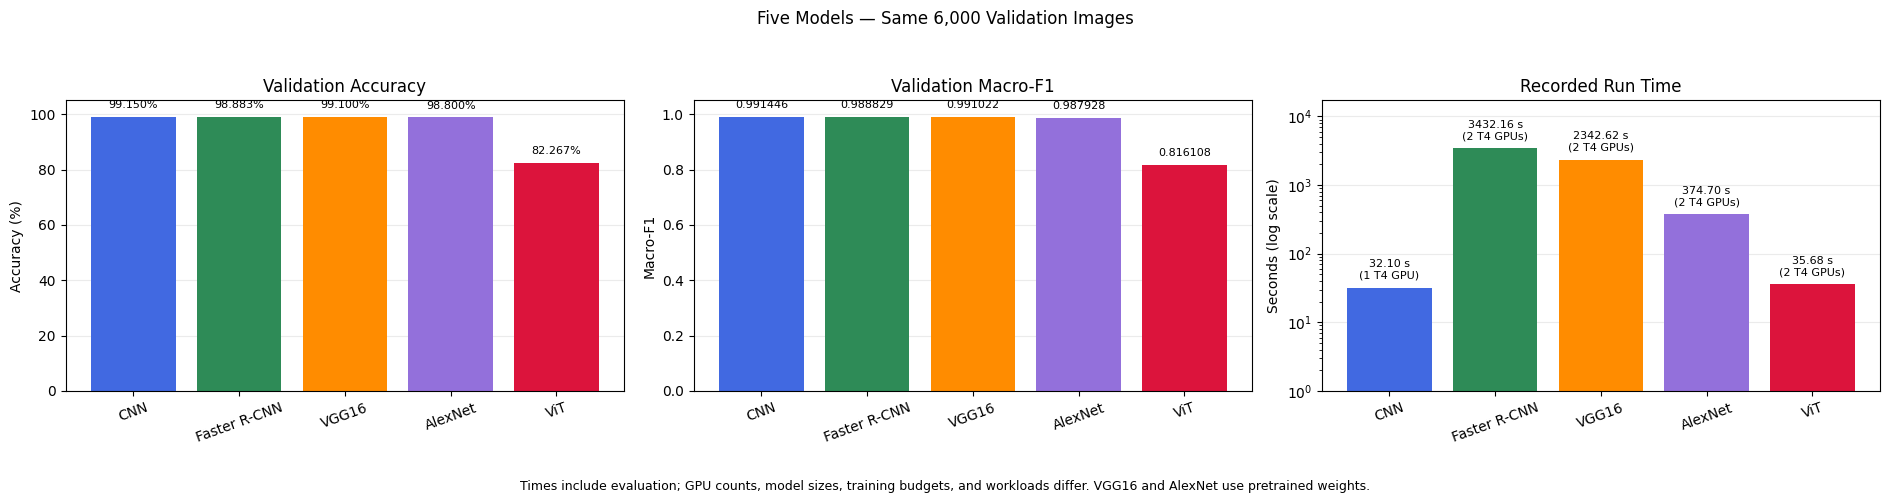

PASS: five-model validation comparison chart saved.
Test set remains unevaluated.


In [25]:
plot_data = all_models_comparison_df.set_index("model").loc[
    ["CNN", "Faster R-CNN", "VGG16", "AlexNet", "ViT"]
].reset_index()

colors = ["royalblue", "seagreen", "darkorange", "mediumpurple", "crimson"]
positions = np.arange(len(plot_data))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

panels = [
    ("accuracy", 100, "Validation Accuracy", "Accuracy (%)"),
    ("macro_f1", 1, "Validation Macro-F1", "Macro-F1"),
    ("training_seconds", 1, "Recorded Run Time", "Seconds (log scale)"),
]

for ax, (column, multiplier, title, ylabel) in zip(axes, panels):
    values = plot_data[column].to_numpy() * multiplier

    ax.bar(positions, values, color=colors)
    ax.set_xticks(positions, plot_data["model"], rotation=20)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    if column == "accuracy":
        ax.set_ylim(0, 105)
    elif column == "macro_f1":
        ax.set_ylim(0, 1.05)
    else:
        ax.set_yscale("log")
        ax.set_ylim(1, values.max() * 5)

    for position, value, gpu_count in zip(
        positions, values, plot_data["gpus_used"]
    ):
        if column == "accuracy":
            label = f"{value:.3f}%"
        elif column == "macro_f1":
            label = f"{value:.6f}"
        else:
            label = (
                f"{value:.2f} s\n"
                f"({gpu_count} T4 GPU{'s' if gpu_count > 1 else ''})"
            )

        ax.annotate(
            label,
            (position, value),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
        )

fig.suptitle("Five Models — Same 6,000 Validation Images")
fig.text(
    0.5,
    0.02,
    "Times include evaluation; GPU counts, model sizes, training budgets, "
    "and workloads differ. VGG16 and AlexNet use pretrained weights.",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.08, 1, 0.94])
fig.savefig(
    PLOTS_DIR / "all_models_validation_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("PASS: five-model validation comparison chart saved.")
print("Test set remains unevaluated.")

### ViT findings and comparison


## Final evaluation: all five models on the official MNIST test set


In [26]:
from pathlib import Path

checkpoint_names = {
    "CNN": "cnn_best.pt",
    "Faster R-CNN": "faster_rcnn_best.pt",
    "VGG16": "vgg16_best.pt",
    "AlexNet": "alexnet_best.pt",
    "ViT": "vit_best.pt",
}

checkpoint_paths = {}

for model_name, filename in checkpoint_names.items():
    matches = sorted(Path("/kaggle/input").rglob(filename))

    if len(matches) != 1:
        raise RuntimeError(
            f"{model_name}: expected one {filename}, found {len(matches)}. "
            f"Matches: {[str(path) for path in matches]}"
        )

    path = matches[0]
    assert path.stat().st_size > 0
    checkpoint_paths[model_name] = path

    print(f"{model_name}: {path}")
    print(f"Size: {path.stat().st_size / 1024**2:.2f} MiB\n")

print("PASS: all five checkpoint files found.")
print("No training or test evaluation performed.")

CNN: /kaggle/input/datasets/soulaimanebenayad/checkpoints/cnn_best.pt
Size: 1.61 MiB

Faster R-CNN: /kaggle/input/datasets/soulaimanebenayad/checkpoints/faster_rcnn_best.pt
Size: 1.86 MiB

VGG16: /kaggle/input/datasets/soulaimanebenayad/checkpoints/vgg16_best.pt
Size: 512.33 MiB

AlexNet: /kaggle/input/datasets/soulaimanebenayad/checkpoints/alexnet_best.pt
Size: 217.62 MiB

ViT: /kaggle/input/datasets/soulaimanebenayad/checkpoints/vit_best.pt
Size: 0.02 MiB

PASS: all five checkpoint files found.
No training or test evaluation performed.


In [27]:
import hashlib
import pandas as pd

expected_hashes = {
    "CNN": "658d4099d36e6ee7e9eda305de2be8b545314af0d2813a3311d5be8ca6c95aae",
    "Faster R-CNN": "52fc738fa03c6634b76548827e639b2bd2206826a0f01598b819ddd1bdcbaa03",
    "VGG16": "fc72f67d10bd1a6e055e77e7382f4afb16e0395d3aac0dbd798eb238e9ef65d1",
    "AlexNet": "ff6bd9d4b932684aa4f1c37d682c67fc539f3edf47dbd9f0412bee1f69068c6b",
}

checkpoint_hashes = {}
hash_records = []

for model_name, path in checkpoint_paths.items():
    digest = hashlib.sha256()

    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)

    actual_hash = digest.hexdigest()
    checkpoint_hashes[model_name] = actual_hash
    expected_hash = expected_hashes.get(model_name)

    if expected_hash is not None and actual_hash != expected_hash:
        raise ValueError(
            f"{model_name}: checkpoint hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Found:    {actual_hash}"
        )

    hash_records.append({
        "model": model_name,
        "sha256": actual_hash,
        "status": (
            "Matches verified local copy"
            if expected_hash is not None
            else "Recorded; no reference hash supplied"
        ),
    })

checkpoint_hash_table = pd.DataFrame(hash_records)
display(checkpoint_hash_table)

print("ViT SHA256:", checkpoint_hashes["ViT"])
print("PASS: four reference hashes match; ViT hash recorded.")
print("No models loaded or test predictions computed.")

,model,sha256,status
0,CNN,658d4099d36e6ee7e9eda305de2be8b545314af0d2813a...,Matches verified local copy
1,Faster R-CNN,52fc738fa03c6634b76548827e639b2bd2206826a0f015...,Matches verified local copy
2,VGG16,fc72f67d10bd1a6e055e77e7382f4afb16e0395d3aac0d...,Matches verified local copy
3,AlexNet,ff6bd9d4b932684aa4f1c37d682c67fc539f3edf47dbd9...,Matches verified local copy
4,ViT,e44b6ad97df884718d0bdbb9f0188e25d1c7f5ee9d5882...,Recorded; no reference hash supplied


ViT SHA256: e44b6ad97df884718d0bdbb9f0188e25d1c7f5ee9d5882c92a6a8483b4083504
PASS: four reference hashes match; ViT hash recorded.
No models loaded or test predictions computed.


In [28]:
import gc
import torch

expected_split_hash = (
    "d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4"
)

expected_epochs = {
    "CNN": 10,
    "Faster R-CNN": 9,
    "VGG16": 4,
    "AlexNet": 5,
    "ViT": 4,
}

checkpoint_metadata = {}
metadata_records = []

for model_name, path in checkpoint_paths.items():
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )

    assert isinstance(checkpoint, dict), model_name
    assert "model_state_dict" in checkpoint, model_name

    config = checkpoint.get("config", {})
    saved_split = checkpoint.get(
        "split_sha256", config.get("split_sha256")
    )
    selected_epoch = checkpoint.get("selected_epoch")
    state = checkpoint["model_state_dict"]

    assert saved_split == expected_split_hash, (
        f"{model_name}: split hash mismatch."
    )
    assert selected_epoch == expected_epochs[model_name], (
        f"{model_name}: unexpected selected epoch {selected_epoch}."
    )
    assert len(state) > 0, f"{model_name}: empty state dictionary."

    for name, tensor in state.items():
        assert isinstance(tensor, torch.Tensor), (
            f"{model_name}: unexpected state entry {name}."
        )
        assert torch.isfinite(tensor).all().item(), (
            f"{model_name}: non-finite values in {name}."
        )

    checkpoint_metadata[model_name] = {
        "selected_epoch": int(selected_epoch),
        "split_sha256": saved_split,
        "sha256": checkpoint_hashes[model_name],
        "config": config,
    }

    metadata_records.append({
        "model": model_name,
        "selected_epoch": selected_epoch,
        "state_tensors": len(state),
        "split_matches": True,
        "finite_weights": True,
    })

    del state, tensor, checkpoint
    gc.collect()

display(pd.DataFrame(metadata_records))

print("PASS: all five selected epochs and split hashes match.")
print("PASS: all saved state tensors are finite.")
print("Checkpoints inspected on CPU; no test predictions computed.")

,model,selected_epoch,state_tensors,split_matches,finite_weights
0,CNN,10,8,True,True
1,Faster R-CNN,9,18,True,True
2,VGG16,4,32,True,True
3,AlexNet,5,16,True,True
4,ViT,4,46,True,True


PASS: all five selected epochs and split hashes match.
PASS: all saved state tensors are finite.
Checkpoints inspected on CPU; no test predictions computed.


In [29]:
import json
from datetime import datetime, timezone
from pathlib import Path

RESULTS_DIR = Path("/kaggle/working/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

selection_rules = {
    "CNN": "lowest validation cross-entropy",
    "Faster R-CNN": "highest validation macro-F1",
    "VGG16": "lowest validation cross-entropy",
    "AlexNet": "lowest validation cross-entropy",
    "ViT": "lowest validation cross-entropy",
}

input_protocols = {
    "CNN": "Grayscale, 1×28×28, pixels divided by 255.",
    "Faster R-CNN": (
        "Three identical grayscale channels, pixels divided by 255; "
        "original detector transform; full-image target box [0, 0, 28, 28]; "
        "detector labels 1–10 map to digits 0–9."
    ),
    "VGG16": (
        "Three identical grayscale channels; IMAGENET1K_V1 preprocessing: "
        "bilinear resize 256, center crop 224, ImageNet normalization."
    ),
    "AlexNet": (
        "Three identical grayscale channels; IMAGENET1K_V1 preprocessing: "
        "bilinear resize 256, center crop 224, ImageNet normalization."
    ),
    "ViT": "Grayscale, 1×28×28, pixels divided by 255; 49 patches of 4×4.",
}

frozen_test_plan = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "split_sha256": expected_split_hash,
    "test_dataset": "Official MNIST test partition",
    "expected_test_samples": 10000,
    "test_image_order": "Original IDX order, source indices 0–9999",
    "preselected_model": "CNN",
    "model_selection_basis": (
        "Highest validation accuracy; CNN also had the highest "
        "validation macro-F1 among the five recorded experiments."
    ),
    "metrics": {
        "accuracy": "All 10,000 test images.",
        "macro_f1": "Unweighted mean across digits 0–9; zero_division=0.",
        "classifier_loss": "Sample-weighted mean cross-entropy.",
        "detector_loss": (
            "Total detection loss reported separately; "
            "not ranked against classifier cross-entropy."
        ),
    },
    "prediction_rules": {
        "classifiers": "Argmax of ten output logits.",
        "Faster R-CNN": (
            "Highest-scoring detection mapped to digit; "
            "missing detection recorded as -1 and counted as incorrect."
        ),
    },
    "training_times": (
        "Retain the previously recorded training times. "
        "Any test evaluation timing is recorded separately."
    ),
    "restrictions": {
        "retraining": False,
        "test_based_tuning": False,
        "test_based_checkpoint_selection": False,
        "test_based_model_reselection": False,
    },
    "models": {
        name: {
            **checkpoint_metadata[name],
            "checkpoint_file": checkpoint_paths[name].name,
            "checkpoint_selection": selection_rules[name],
            "input_protocol": input_protocols[name],
        }
        for name in checkpoint_paths
    },
    "test_evaluated_at_freeze": False,
}

frozen_plan_path = RESULTS_DIR / "all_models_frozen_test_plan.json"

if frozen_plan_path.exists():
    raise FileExistsError(
        f"{frozen_plan_path} already exists. Inspect it before replacing."
    )

with frozen_plan_path.open("w", encoding="utf-8") as file:
    json.dump(frozen_test_plan, file, indent=2, allow_nan=False)

print("Preselected model:", frozen_test_plan["preselected_model"])
print("Frozen checkpoint epochs:", expected_epochs)
print("Expected test images:", frozen_test_plan["expected_test_samples"])
print("Saved:", frozen_plan_path)
print("PASS: evaluation plan frozen before test predictions.")

Preselected model: CNN
Frozen checkpoint epochs: {'CNN': 10, 'Faster R-CNN': 9, 'VGG16': 4, 'AlexNet': 5, 'ViT': 4}
Expected test images: 10000
Saved: /kaggle/working/results/all_models_frozen_test_plan.json
PASS: evaluation plan frozen before test predictions.


In [30]:
import hashlib
import struct
import numpy as np
import torch
from pathlib import Path

test_file_specs = {
    "images": {
        "filename": "t10k-images-idx3-ubyte",
        "sha256": "0fa7898d509279e482958e8ce81c8e77db3f2f8254e26661ceb7762c4d494ce7",
    },
    "labels": {
        "filename": "t10k-labels-idx1-ubyte",
        "sha256": "ff7bcfd416de33731a308c3f266cc351222c34898ecbeaf847f06e48f7ec33f2",
    },
}

test_file_bytes = {}

for name, spec in test_file_specs.items():
    matches = sorted(
        path
        for path in Path("/kaggle/input").rglob(spec["filename"])
        if path.is_file()
    )
    assert matches, f"Missing official test {name} file."

    for path in matches:
        content = path.read_bytes()
        actual_hash = hashlib.sha256(content).hexdigest()
        assert actual_hash == spec["sha256"], (
            f"Unexpected test file contents: {path}"
        )

    test_file_bytes[name] = content
    print(f"{name}: {matches[0]} ({len(matches)} matching copies)")

image_bytes = test_file_bytes["images"]
label_bytes = test_file_bytes["labels"]

magic, count, height, width = struct.unpack(">IIII", image_bytes[:16])
label_magic, label_count = struct.unpack(">II", label_bytes[:8])

assert (magic, count, height, width) == (2051, 10000, 28, 28)
assert (label_magic, label_count) == (2049, 10000)
assert len(image_bytes) == 16 + count * height * width
assert len(label_bytes) == 8 + label_count

test_images_uint8 = np.frombuffer(
    image_bytes, dtype=np.uint8, offset=16
).reshape(count, height, width).copy()

test_labels_array = np.frombuffer(
    label_bytes, dtype=np.uint8, offset=8
).astype(np.int64)

expected_test_counts = np.array(
    [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]
)

assert np.all((test_labels_array >= 0) & (test_labels_array <= 9))
assert np.array_equal(
    np.bincount(test_labels_array, minlength=10),
    expected_test_counts,
)

X_test = torch.from_numpy(test_images_uint8).unsqueeze(1).float().div(255)
y_test = torch.from_numpy(test_labels_array)
test_source_indices = np.arange(count, dtype=np.int64)

assert X_test.shape == (10000, 1, 28, 28)
assert y_test.shape == (10000,)
assert torch.isfinite(X_test).all()
assert 0 <= X_test.min().item() <= X_test.max().item() <= 1

display(pd.DataFrame({
    "digit": np.arange(10),
    "test_samples": expected_test_counts,
}))

print("Test tensors:", X_test.shape, y_test.shape)
print("Dtypes:", X_test.dtype, y_test.dtype)
print("PASS: official test hashes, IDX structure, and class counts match.")
print("All images retain their original IDX order.")
print("No test predictions computed.")

images: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte (1 matching copies)
labels: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte (1 matching copies)


,digit,test_samples
0,0,980
1,1,1135
2,2,1032
3,3,1010
4,4,982
5,5,892
6,6,958
7,7,1028
8,8,974
9,9,1009


Test tensors: torch.Size([10000, 1, 28, 28]) torch.Size([10000])
Dtypes: torch.float32 torch.int64
PASS: official test hashes, IDX structure, and class counts match.
All images retain their original IDX order.
No test predictions computed.


In [31]:
import time
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score

device = torch.device("cuda:0")
assert torch.cuda.is_available()

class FrozenMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10),
        )

    def forward(self, images):
        return self.classifier(self.features(images))

cnn_test_model = FrozenMNISTCNN()
checkpoint = torch.load(
    checkpoint_paths["CNN"],
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["selected_epoch"] == 10
cnn_test_model.load_state_dict(checkpoint["model_state_dict"], strict=True)
del checkpoint

cnn_test_model.to(device).eval()

test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

loss_sum = 0.0
evaluated_samples = 0
prediction_batches = []
label_batches = []

torch.cuda.synchronize()
evaluation_start = time.perf_counter()

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = cnn_test_model(images)

        assert torch.isfinite(logits).all()
        loss_sum += nn.functional.cross_entropy(
            logits, labels, reduction="sum"
        ).item()

        evaluated_samples += labels.numel()
        prediction_batches.append(logits.argmax(dim=1).cpu().numpy())
        label_batches.append(labels.cpu().numpy())

torch.cuda.synchronize()
cnn_test_seconds = time.perf_counter() - evaluation_start

cnn_test_predictions = np.concatenate(prediction_batches)
evaluated_labels = np.concatenate(label_batches)

assert evaluated_samples == 10000
assert np.array_equal(evaluated_labels, test_labels_array)

cnn_test_metrics = {
    "model": "CNN",
    "selected_epoch": 10,
    "test_samples": evaluated_samples,
    "loss": loss_sum / evaluated_samples,
    "loss_type": "Cross-entropy",
    "accuracy": accuracy_score(evaluated_labels, cnn_test_predictions),
    "macro_f1": f1_score(
        evaluated_labels,
        cnn_test_predictions,
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    ),
    "errors": int((cnn_test_predictions != evaluated_labels).sum()),
    "test_evaluation_seconds": cnn_test_seconds,
}

cnn_test_predictions_df = pd.DataFrame({
    "source_index": test_source_indices,
    "true_digit": evaluated_labels,
    "predicted_digit": cnn_test_predictions,
    "correct": cnn_test_predictions == evaluated_labels,
})

cnn_test_predictions_df.to_csv(
    RESULTS_DIR / "cnn_test_predictions.csv", index=False
)
pd.DataFrame([cnn_test_metrics]).to_csv(
    RESULTS_DIR / "cnn_test_metrics.csv", index=False
)

display(pd.DataFrame([cnn_test_metrics]))

cnn_test_model.cpu()
del cnn_test_model
gc.collect()
torch.cuda.empty_cache()

print("PASS: frozen CNN evaluated on all 10,000 official test images.")
print("Predictions and metrics saved; no training or reselection performed.")

,model,selected_epoch,test_samples,loss,loss_type,accuracy,macro_f1,errors,test_evaluation_seconds
0,CNN,10,10000,0.025752,Cross-entropy,0.992,0.991954,80,1.085577


PASS: frozen CNN evaluated on all 10,000 official test images.
Predictions and metrics saved; no training or reselection performed.


In [32]:
from torchvision.models import vgg16, VGG16_Weights

vgg16_test_transform = VGG16_Weights.IMAGENET1K_V1.transforms()

vgg16_test_model = vgg16(weights=None)
vgg16_test_model.classifier[6] = nn.Linear(4096, 10)

checkpoint = torch.load(
    checkpoint_paths["VGG16"],
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["selected_epoch"] == 4
vgg16_test_model.load_state_dict(
    checkpoint["model_state_dict"], strict=True
)
del checkpoint

vgg16_test_model.to(device).eval()

vgg16_test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

loss_sum = 0.0
evaluated_samples = 0
prediction_batches = []
label_batches = []

torch.cuda.synchronize()
evaluation_start = time.perf_counter()

with torch.inference_mode():
    for images, labels in vgg16_test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        images = vgg16_test_transform(images.repeat(1, 3, 1, 1))
        assert images.shape[1:] == (3, 224, 224)

        logits = vgg16_test_model(images)
        assert torch.isfinite(logits).all()

        loss_sum += nn.functional.cross_entropy(
            logits, labels, reduction="sum"
        ).item()

        evaluated_samples += labels.numel()
        prediction_batches.append(logits.argmax(dim=1).cpu().numpy())
        label_batches.append(labels.cpu().numpy())

torch.cuda.synchronize()
vgg16_test_seconds = time.perf_counter() - evaluation_start

vgg16_test_predictions = np.concatenate(prediction_batches)
evaluated_labels = np.concatenate(label_batches)

assert evaluated_samples == 10000
assert np.array_equal(evaluated_labels, test_labels_array)

vgg16_test_metrics = {
    "model": "VGG16",
    "selected_epoch": 4,
    "test_samples": evaluated_samples,
    "loss": loss_sum / evaluated_samples,
    "loss_type": "Cross-entropy",
    "accuracy": accuracy_score(evaluated_labels, vgg16_test_predictions),
    "macro_f1": f1_score(
        evaluated_labels,
        vgg16_test_predictions,
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    ),
    "errors": int((vgg16_test_predictions != evaluated_labels).sum()),
    "test_evaluation_seconds": vgg16_test_seconds,
}

vgg16_test_predictions_df = pd.DataFrame({
    "source_index": test_source_indices,
    "true_digit": evaluated_labels,
    "predicted_digit": vgg16_test_predictions,
    "correct": vgg16_test_predictions == evaluated_labels,
})

vgg16_test_predictions_df.to_csv(
    RESULTS_DIR / "vgg16_test_predictions.csv", index=False
)
pd.DataFrame([vgg16_test_metrics]).to_csv(
    RESULTS_DIR / "vgg16_test_metrics.csv", index=False
)

display(pd.DataFrame([vgg16_test_metrics]))

vgg16_test_model.cpu()
del vgg16_test_model, images, labels, logits
gc.collect()
torch.cuda.empty_cache()

print("PASS: frozen VGG16 evaluated on all 10,000 official test images.")
print("Evaluation timing includes input preprocessing.")
print("Predictions and metrics saved; no training or reselection performed.")

,model,selected_epoch,test_samples,loss,loss_type,accuracy,macro_f1,errors,test_evaluation_seconds
0,VGG16,4,10000,0.036427,Cross-entropy,0.9912,0.991195,88,52.995959


PASS: frozen VGG16 evaluated on all 10,000 official test images.
Evaluation timing includes input preprocessing.
Predictions and metrics saved; no training or reselection performed.


In [33]:
from torchvision.models import alexnet, AlexNet_Weights

alexnet_test_transform = AlexNet_Weights.IMAGENET1K_V1.transforms()

alexnet_test_model = alexnet(weights=None)
alexnet_test_model.classifier[6] = nn.Linear(4096, 10)

checkpoint = torch.load(
    checkpoint_paths["AlexNet"],
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["selected_epoch"] == 5
alexnet_test_model.load_state_dict(
    checkpoint["model_state_dict"], strict=True
)
del checkpoint

alexnet_test_model.to(device).eval()

alexnet_test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

loss_sum = 0.0
evaluated_samples = 0
prediction_batches = []
label_batches = []

torch.cuda.synchronize()
evaluation_start = time.perf_counter()

with torch.inference_mode():
    for images, labels in alexnet_test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        images = alexnet_test_transform(images.repeat(1, 3, 1, 1))
        assert images.shape[1:] == (3, 224, 224)

        logits = alexnet_test_model(images)
        assert torch.isfinite(logits).all()

        loss_sum += nn.functional.cross_entropy(
            logits, labels, reduction="sum"
        ).item()

        evaluated_samples += labels.numel()
        prediction_batches.append(logits.argmax(dim=1).cpu().numpy())
        label_batches.append(labels.cpu().numpy())

torch.cuda.synchronize()
alexnet_test_seconds = time.perf_counter() - evaluation_start

alexnet_test_predictions = np.concatenate(prediction_batches)
evaluated_labels = np.concatenate(label_batches)

assert evaluated_samples == 10000
assert np.array_equal(evaluated_labels, test_labels_array)

alexnet_test_metrics = {
    "model": "AlexNet",
    "selected_epoch": 5,
    "test_samples": evaluated_samples,
    "loss": loss_sum / evaluated_samples,
    "loss_type": "Cross-entropy",
    "accuracy": accuracy_score(evaluated_labels, alexnet_test_predictions),
    "macro_f1": f1_score(
        evaluated_labels,
        alexnet_test_predictions,
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    ),
    "errors": int((alexnet_test_predictions != evaluated_labels).sum()),
    "test_evaluation_seconds": alexnet_test_seconds,
}

alexnet_test_predictions_df = pd.DataFrame({
    "source_index": test_source_indices,
    "true_digit": evaluated_labels,
    "predicted_digit": alexnet_test_predictions,
    "correct": alexnet_test_predictions == evaluated_labels,
})

alexnet_test_predictions_df.to_csv(
    RESULTS_DIR / "alexnet_test_predictions.csv", index=False
)
pd.DataFrame([alexnet_test_metrics]).to_csv(
    RESULTS_DIR / "alexnet_test_metrics.csv", index=False
)

display(pd.DataFrame([alexnet_test_metrics]))

alexnet_test_model.cpu()
del alexnet_test_model, images, labels, logits
gc.collect()
torch.cuda.empty_cache()

print("PASS: frozen AlexNet evaluated on all 10,000 official test images.")
print("Evaluation timing includes input preprocessing.")
print("Predictions and metrics saved; no training or reselection performed.")

,model,selected_epoch,test_samples,loss,loss_type,accuracy,macro_f1,errors,test_evaluation_seconds
0,AlexNet,5,10000,0.031898,Cross-entropy,0.9898,0.989694,102,3.28913


PASS: frozen AlexNet evaluated on all 10,000 official test images.
Evaluation timing includes input preprocessing.
Predictions and metrics saved; no training or reselection performed.


In [34]:
import copy

vit_test_model = copy.deepcopy(vit_model).cpu()

checkpoint = torch.load(
    checkpoint_paths["ViT"],
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["selected_epoch"] == 4
vit_test_model.load_state_dict(
    checkpoint["model_state_dict"], strict=True
)
del checkpoint

assert sum(p.numel() for p in vit_test_model.parameters()) == 1642
vit_test_model.to(device).eval()

vit_test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

loss_sum = 0.0
evaluated_samples = 0
prediction_batches = []
label_batches = []

torch.cuda.synchronize()
evaluation_start = time.perf_counter()

with torch.inference_mode():
    for images, labels in vit_test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = vit_test_model(images)
        assert logits.shape == (labels.numel(), 10)
        assert torch.isfinite(logits).all()

        loss_sum += nn.functional.cross_entropy(
            logits, labels, reduction="sum"
        ).item()

        evaluated_samples += labels.numel()
        prediction_batches.append(logits.argmax(dim=1).cpu().numpy())
        label_batches.append(labels.cpu().numpy())

torch.cuda.synchronize()
vit_test_seconds = time.perf_counter() - evaluation_start

vit_test_predictions = np.concatenate(prediction_batches)
evaluated_labels = np.concatenate(label_batches)

assert evaluated_samples == 10000
assert np.array_equal(evaluated_labels, test_labels_array)

vit_test_metrics = {
    "model": "ViT",
    "selected_epoch": 4,
    "test_samples": evaluated_samples,
    "loss": loss_sum / evaluated_samples,
    "loss_type": "Cross-entropy",
    "accuracy": accuracy_score(evaluated_labels, vit_test_predictions),
    "macro_f1": f1_score(
        evaluated_labels,
        vit_test_predictions,
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    ),
    "errors": int((vit_test_predictions != evaluated_labels).sum()),
    "test_evaluation_seconds": vit_test_seconds,
}

vit_test_predictions_df = pd.DataFrame({
    "source_index": test_source_indices,
    "true_digit": evaluated_labels,
    "predicted_digit": vit_test_predictions,
    "correct": vit_test_predictions == evaluated_labels,
})

vit_test_predictions_df.to_csv(
    RESULTS_DIR / "vit_test_predictions.csv", index=False
)
pd.DataFrame([vit_test_metrics]).to_csv(
    RESULTS_DIR / "vit_test_metrics.csv", index=False
)

display(pd.DataFrame([vit_test_metrics]))

vit_test_model.cpu()
del vit_test_model, images, labels, logits
gc.collect()
torch.cuda.empty_cache()

print("PASS: frozen ViT evaluated on all 10,000 official test images.")
print("Predictions and metrics saved; no training or reselection performed.")

,model,selected_epoch,test_samples,loss,loss_type,accuracy,macro_f1,errors,test_evaluation_seconds
0,ViT,4,10000,0.49238,Cross-entropy,0.8279,0.822109,1721,0.223489


PASS: frozen ViT evaluated on all 10,000 official test images.
Predictions and metrics saved; no training or reselection performed.


In [35]:
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import (
    TwoMLPHead,
    FastRCNNPredictor,
)
from torchvision.ops import MultiScaleRoIAlign

rcnn_backbone = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
)
rcnn_backbone.out_channels = 64

rcnn_test_model = FasterRCNN(
    backbone=rcnn_backbone,
    num_classes=None,
    min_size=28,
    max_size=28,
    image_mean=[0.0, 0.0, 0.0],
    image_std=[1.0, 1.0, 1.0],
    rpn_anchor_generator=AnchorGenerator(
        sizes=((16, 28, 40),),
        aspect_ratios=((0.5, 1.0, 2.0),),
    ),
    box_roi_pool=MultiScaleRoIAlign(
        featmap_names=["0"],
        output_size=7,
        sampling_ratio=2,
    ),
    box_head=TwoMLPHead(64 * 7 * 7, 128),
    box_predictor=FastRCNNPredictor(128, 11),
    rpn_pre_nms_top_n_train=200,
    rpn_pre_nms_top_n_test=200,
    rpn_post_nms_top_n_train=50,
    rpn_post_nms_top_n_test=50,
    rpn_batch_size_per_image=128,
    box_batch_size_per_image=64,
    box_score_thresh=0.0,
    box_nms_thresh=0.5,
    box_detections_per_img=1,
)

checkpoint = torch.load(
    checkpoint_paths["Faster R-CNN"],
    map_location="cpu",
    weights_only=True,
)

assert checkpoint["selected_epoch"] == 9
rcnn_test_model.load_state_dict(
    checkpoint["model_state_dict"], strict=True
)
del checkpoint

parameter_count = sum(
    parameter.numel() for parameter in rcnn_test_model.parameters()
)
assert parameter_count == 484388

rcnn_test_model.to(device).eval()

print("Selected epoch: 9")
print("Parameters:", parameter_count)
print("Device:", next(rcnn_test_model.parameters()).device)
print("Detector classes: background + digits 0–9.")
print("PASS: original Faster R-CNN architecture and saved weights restored.")
print("No new test predictions computed.")

Selected epoch: 9
Parameters: 484388
Device: cuda:0
Detector classes: background + digits 0–9.
PASS: original Faster R-CNN architecture and saved weights restored.
No new test predictions computed.


In [36]:
rcnn_test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

rcnn_test_model.eval()
prediction_batches = []
score_batches = []
label_batches = []
evaluated_samples = 0

torch.cuda.synchronize()
evaluation_start = time.perf_counter()

with torch.inference_mode():
    for images, labels in rcnn_test_loader:
        images = images.to(device, non_blocking=True)
        detector_images = list(images.repeat(1, 3, 1, 1))
        outputs = rcnn_test_model(detector_images)

        assert len(outputs) == labels.numel()

        batch_predictions = []
        batch_scores = []

        for output in outputs:
            assert torch.isfinite(output["scores"]).all()
            assert torch.isfinite(output["boxes"]).all()

            if output["scores"].numel() == 0:
                batch_predictions.append(-1)
                batch_scores.append(0.0)
            else:
                best_index = output["scores"].argmax().item()
                detector_label = output["labels"][best_index].item()
                assert 1 <= detector_label <= 10

                batch_predictions.append(detector_label - 1)
                batch_scores.append(
                    output["scores"][best_index].item()
                )

        prediction_batches.append(
            np.asarray(batch_predictions, dtype=np.int64)
        )
        score_batches.append(
            np.asarray(batch_scores, dtype=np.float64)
        )
        label_batches.append(labels.numpy())
        evaluated_samples += labels.numel()

torch.cuda.synchronize()
rcnn_test_inference_seconds = time.perf_counter() - evaluation_start

rcnn_test_predictions = np.concatenate(prediction_batches)
rcnn_test_scores = np.concatenate(score_batches)
evaluated_labels = np.concatenate(label_batches)

assert evaluated_samples == 10000
assert np.array_equal(evaluated_labels, test_labels_array)

rcnn_test_metrics = {
    "model": "Faster R-CNN",
    "selected_epoch": 9,
    "test_samples": evaluated_samples,
    "accuracy": accuracy_score(evaluated_labels, rcnn_test_predictions),
    "macro_f1": f1_score(
        evaluated_labels,
        rcnn_test_predictions,
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    ),
    "errors": int((rcnn_test_predictions != evaluated_labels).sum()),
    "missing_detections": int((rcnn_test_predictions == -1).sum()),
    "test_inference_seconds": rcnn_test_inference_seconds,
}

rcnn_test_predictions_df = pd.DataFrame({
    "source_index": test_source_indices,
    "true_digit": evaluated_labels,
    "predicted_digit": rcnn_test_predictions,
    "detection_score": rcnn_test_scores,
    "correct": rcnn_test_predictions == evaluated_labels,
})

rcnn_test_predictions_df.to_csv(
    RESULTS_DIR / "faster_rcnn_test_predictions.csv", index=False
)
pd.DataFrame([rcnn_test_metrics]).to_csv(
    RESULTS_DIR / "faster_rcnn_test_metrics.csv", index=False
)

display(pd.DataFrame([rcnn_test_metrics]))

print("PASS: frozen detector evaluated on all 10,000 official test images.")
print("Missing detections count as incorrect predictions.")
print("Predictions and classification metrics saved.")
print("No training or reselection performed.")

,model,selected_epoch,test_samples,accuracy,macro_f1,errors,missing_detections,test_inference_seconds
0,Faster R-CNN,9,10000,0.99,0.989896,100,0,24.675044


PASS: frozen detector evaluated on all 10,000 official test images.
Missing detections count as incorrect predictions.
Predictions and classification metrics saved.
No training or reselection performed.


In [37]:
loss_component_names = [
    "loss_classifier",
    "loss_box_reg",
    "loss_objectness",
    "loss_rpn_box_reg",
]

rcnn_state_before_loss = {
    name: tensor.detach().cpu().clone()
    for name, tensor in rcnn_test_model.state_dict().items()
}
previous_mode = rcnn_test_model.training

component_sums = {name: 0.0 for name in loss_component_names}
loss_samples = 0

torch.cuda.synchronize()
loss_start = time.perf_counter()

try:
    with torch.random.fork_rng(devices=list(range(torch.cuda.device_count()))):
        torch.manual_seed(42)
        torch.cuda.manual_seed_all(42)
        rcnn_test_model.train()

        with torch.no_grad():
            for images, labels in rcnn_test_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                detector_images = list(images.repeat(1, 3, 1, 1))
                targets = [
                    {
                        "boxes": torch.tensor(
                            [[0.0, 0.0, 28.0, 28.0]],
                            dtype=torch.float32,
                            device=device,
                        ),
                        "labels": label.reshape(1) + 1,
                    }
                    for label in labels
                ]

                losses = rcnn_test_model(detector_images, targets)
                assert set(losses) == set(loss_component_names)

                batch_size = labels.numel()

                for name in loss_component_names:
                    assert torch.isfinite(losses[name]).item()
                    component_sums[name] += losses[name].item() * batch_size

                loss_samples += batch_size
finally:
    rcnn_test_model.train(previous_mode)

torch.cuda.synchronize()
rcnn_test_loss_seconds = time.perf_counter() - loss_start

assert loss_samples == 10000

for name, tensor in rcnn_test_model.state_dict().items():
    assert torch.equal(
        tensor.detach().cpu(), rcnn_state_before_loss[name]
    ), f"Model state changed: {name}"

component_means = {
    name: total / loss_samples
    for name, total in component_sums.items()
}

rcnn_test_metrics.update({
    "loss": sum(component_means.values()),
    "loss_type": "Total detection loss",
    **component_means,
    "test_loss_seconds": rcnn_test_loss_seconds,
    "test_evaluation_seconds": (
        rcnn_test_inference_seconds + rcnn_test_loss_seconds
    ),
    "loss_sampling_seed": 42,
    "loss_batch_size": 32,
})

pd.DataFrame([rcnn_test_metrics]).to_csv(
    RESULTS_DIR / "faster_rcnn_test_metrics.csv", index=False
)

display(pd.DataFrame([{
    "loss": rcnn_test_metrics["loss"],
    **component_means,
}]))

rcnn_test_model.cpu()
del rcnn_state_before_loss, images, labels, detector_images, targets, losses
gc.collect()
torch.cuda.empty_cache()

print("PASS: image-weighted detection loss measured over 10,000 images.")
print("PASS: model state unchanged; previous mode and RNG state restored.")
print("Detection loss is interpreted separately from classifier cross-entropy.")
print("No optimizer updates or reselection performed.")

,loss,loss_classifier,loss_box_reg,loss_objectness,loss_rpn_box_reg
0,0.0318,0.018472,0.013282,1.714270e-07,0.000046


PASS: image-weighted detection loss measured over 10,000 images.
PASS: model state unchanged; previous mode and RNG state restored.
Detection loss is interpreted separately from classifier cross-entropy.
No optimizer updates or reselection performed.


In [38]:
model_files = {
    "CNN": "cnn",
    "Faster R-CNN": "faster_rcnn",
    "VGG16": "vgg16",
    "AlexNet": "alexnet",
    "ViT": "vit",
}

verified_test_records = []
verified_test_predictions = {}

for model_name, prefix in model_files.items():
    predictions = pd.read_csv(
        RESULTS_DIR / f"{prefix}_test_predictions.csv"
    )
    saved_metrics = pd.read_csv(
        RESULTS_DIR / f"{prefix}_test_metrics.csv"
    )

    assert len(saved_metrics) == 1
    saved = saved_metrics.iloc[0]
    assert saved["model"] == model_name
    assert int(saved["selected_epoch"]) == expected_epochs[model_name]
    assert len(predictions) == 10000
    assert not predictions["source_index"].duplicated().any()

    predictions = predictions.sort_values("source_index").reset_index(drop=True)

    assert np.array_equal(
        predictions["source_index"].to_numpy(), test_source_indices
    )
    assert np.array_equal(
        predictions["true_digit"].to_numpy(), test_labels_array
    )

    y_true = predictions["true_digit"].to_numpy()
    y_pred = predictions["predicted_digit"].to_numpy()

    allowed_labels = np.arange(-1, 10) if model_name == "Faster R-CNN" else np.arange(10)
    assert np.isin(y_pred, allowed_labels).all()

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    )
    errors = int((y_pred != y_true).sum())
    missing = int((y_pred == -1).sum())

    assert np.isclose(accuracy, saved["accuracy"], rtol=0, atol=1e-12)
    assert np.isclose(macro_f1, saved["macro_f1"], rtol=0, atol=1e-12)
    assert errors == int(saved["errors"])
    assert np.isfinite(saved["loss"]) and saved["loss"] >= 0

    if model_name == "Faster R-CNN":
        assert missing == int(saved["missing_detections"])

    verified_test_predictions[model_name] = predictions
    verified_test_records.append({
        "model": model_name,
        "selected_epoch": int(saved["selected_epoch"]),
        "test_samples": len(predictions),
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "errors": errors,
        "missing_detections": missing,
        "loss": float(saved["loss"]),
        "loss_type": saved["loss_type"],
        "test_evaluation_seconds": float(saved["test_evaluation_seconds"]),
        "preselected_model": model_name == frozen_test_plan["preselected_model"],
    })

all_models_test_comparison = pd.DataFrame(verified_test_records)

all_models_test_comparison.to_csv(
    RESULTS_DIR / "all_models_test_comparison.csv",
    index=False,
)

display(all_models_test_comparison)

print("PASS: identical official test image IDs and labels across all five models.")
print("PASS: saved predictions reproduce every accuracy, macro-F1, and error count.")
print("Preselected model remains:", frozen_test_plan["preselected_model"])
print("Detection loss is interpreted separately.")
print("No additional inference, training, or reselection performed.")

,model,selected_epoch,test_samples,accuracy,macro_f1,errors,missing_detections,loss,loss_type,test_evaluation_seconds,preselected_model
0,CNN,10,10000,0.9920,0.991954,80,0,0.025752,Cross-entropy,1.085577,True
1,Faster R-CNN,9,10000,0.9900,0.989896,100,0,0.031800,Total detection loss,61.647632,False
2,VGG16,4,10000,0.9912,0.991195,88,0,0.036427,Cross-entropy,52.995959,False
3,AlexNet,5,10000,0.9898,0.989694,102,0,0.031898,Cross-entropy,3.289130,False
4,ViT,4,10000,0.8279,0.822109,1721,0,0.492380,Cross-entropy,0.223489,False


PASS: identical official test image IDs and labels across all five models.
PASS: saved predictions reproduce every accuracy, macro-F1, and error count.
Preselected model remains: CNN
Detection loss is interpreted separately.
No additional inference, training, or reselection performed.


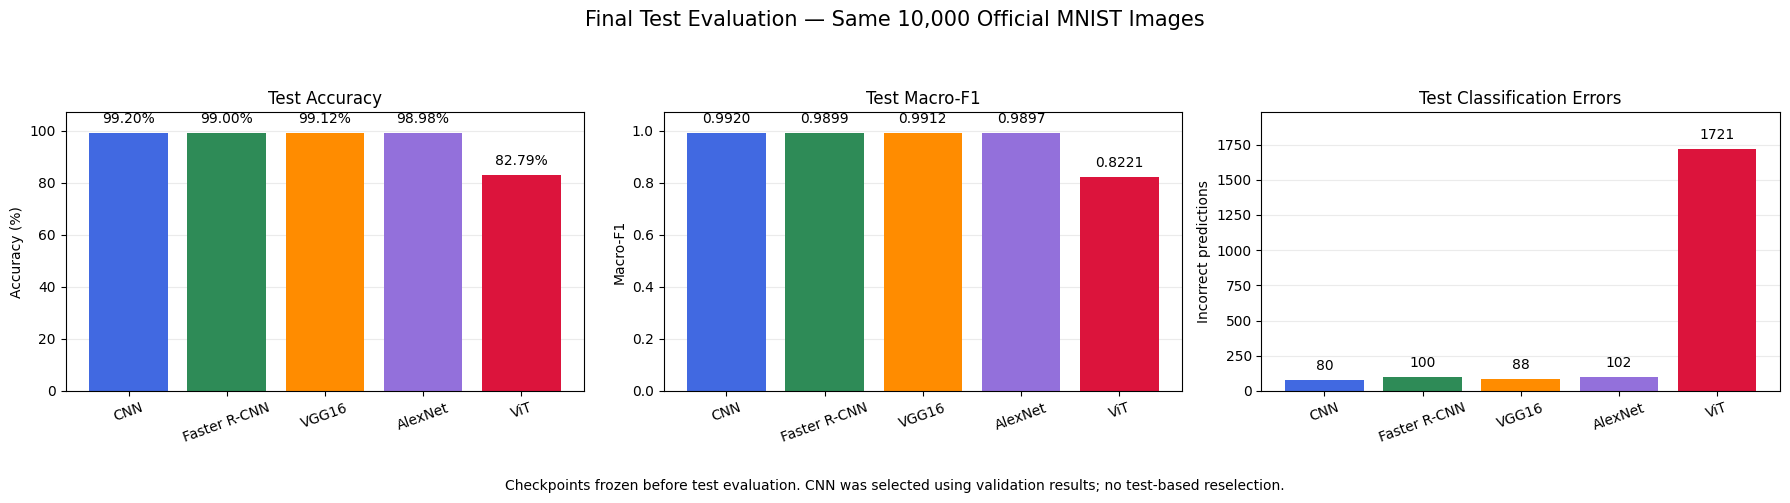

Saved: /kaggle/working/plots/all_models_test_comparison.png
PASS: final test comparison plotted from verified saved results.


In [39]:
import matplotlib.pyplot as plt

PLOTS_DIR = Path("/kaggle/working/plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

plot_data = all_models_test_comparison.set_index("model").loc[
    ["CNN", "Faster R-CNN", "VGG16", "AlexNet", "ViT"]
]

model_names = plot_data.index.tolist()
colors = ["royalblue", "seagreen", "darkorange", "mediumpurple", "crimson"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [
    ("accuracy", 100, "Test Accuracy", "Accuracy (%)", "{:.2f}%"),
    ("macro_f1", 1, "Test Macro-F1", "Macro-F1", "{:.4f}"),
    ("errors", 1, "Test Classification Errors", "Incorrect predictions", "{:.0f}"),
]

for ax, (column, multiplier, title, ylabel, label_format) in zip(axes, panels):
    values = plot_data[column].to_numpy() * multiplier
    bars = ax.bar(model_names, values, color=colors)

    ax.bar_label(
        bars,
        labels=[label_format.format(value) for value in values],
        padding=5,
        fontsize=10,
    )
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=20)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

    if column == "accuracy":
        ax.set_ylim(0, 107)
    elif column == "macro_f1":
        ax.set_ylim(0, 1.07)
    else:
        ax.set_ylim(0, values.max() * 1.15)

fig.suptitle(
    "Final Test Evaluation — Same 10,000 Official MNIST Images",
    fontsize=15,
)
fig.text(
    0.5,
    0.02,
    "Checkpoints frozen before test evaluation. "
    "CNN was selected using validation results; no test-based reselection.",
    ha="center",
    fontsize=10,
)

fig.tight_layout(rect=[0, 0.08, 1, 0.92])

figure_path = PLOTS_DIR / "all_models_test_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", figure_path)
print("PASS: final test comparison plotted from verified saved results.")

,model,validation_accuracy,validation_macro_f1,test_accuracy,test_macro_f1,accuracy_change_pp
0,CNN,0.991500,0.991446,0.9920,0.991954,0.050000
1,Faster R-CNN,0.988833,0.988829,0.9900,0.989896,0.116667
2,VGG16,0.991000,0.991022,0.9912,0.991195,0.020000
3,AlexNet,0.988000,0.987928,0.9898,0.989694,0.180000
4,ViT,0.822667,0.816108,0.8279,0.822109,0.523333


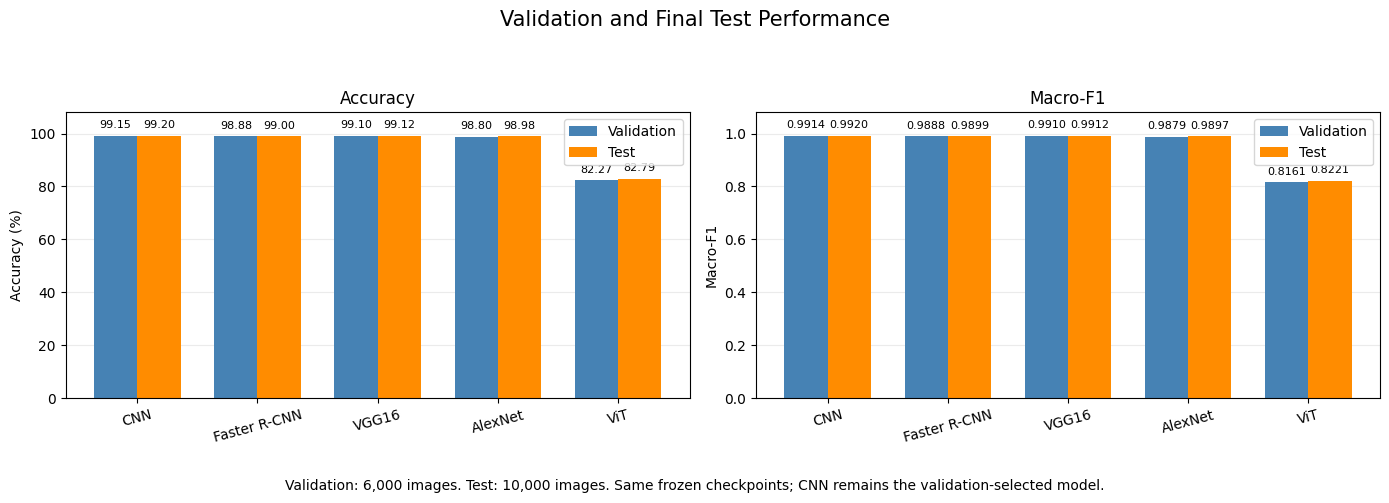

Saved: /kaggle/working/plots/all_models_validation_test_comparison.png
Accuracy changes are expressed in percentage points.
No additional inference, training, or reselection performed.


In [40]:
validation_path = RESULTS_DIR / "all_models_validation_comparison.csv"

if not validation_path.exists():
    matches = sorted(
        Path("/kaggle/input").rglob("all_models_validation_comparison.csv")
    )
    if len(matches) != 1:
        raise FileNotFoundError(
            "Expected one saved all_models_validation_comparison.csv. "
            f"Found: {[str(path) for path in matches]}"
        )
    validation_path = matches[0]

validation_results = pd.read_csv(validation_path)
model_order = ["CNN", "Faster R-CNN", "VGG16", "AlexNet", "ViT"]

assert not validation_results["model"].duplicated().any()
assert set(validation_results["model"]) == set(model_order)

validation_test_comparison = (
    validation_results[["model", "accuracy", "macro_f1"]]
    .rename(columns={
        "accuracy": "validation_accuracy",
        "macro_f1": "validation_macro_f1",
    })
    .merge(
        all_models_test_comparison[["model", "accuracy", "macro_f1"]],
        on="model",
        validate="one_to_one",
    )
    .rename(columns={
        "accuracy": "test_accuracy",
        "macro_f1": "test_macro_f1",
    })
    .set_index("model")
    .loc[model_order]
    .reset_index()
)

validation_test_comparison["accuracy_change_pp"] = 100 * (
    validation_test_comparison["test_accuracy"]
    - validation_test_comparison["validation_accuracy"]
)

validation_test_comparison.to_csv(
    RESULTS_DIR / "all_models_validation_test_comparison.csv",
    index=False,
)

display(validation_test_comparison)

positions = np.arange(len(model_order))
bar_width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, multiplier, title, ylabel in [
    (axes[0], "accuracy", 100, "Accuracy", "Accuracy (%)"),
    (axes[1], "macro_f1", 1, "Macro-F1", "Macro-F1"),
]:
    for offset, split, color in [
        (-bar_width / 2, "validation", "steelblue"),
        (bar_width / 2, "test", "darkorange"),
    ]:
        values = validation_test_comparison[f"{split}_{metric}"] * multiplier
        bars = ax.bar(
            positions + offset,
            values,
            width=bar_width,
            label=split.capitalize(),
            color=color,
        )
        ax.bar_label(
            bars,
            fmt="%.2f" if metric == "accuracy" else "%.4f",
            padding=4,
            fontsize=8,
        )

    ax.set_xticks(positions, model_order, rotation=15)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 108 if metric == "accuracy" else 1.08)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

fig.suptitle("Validation and Final Test Performance", fontsize=15)
fig.text(
    0.5, 0.02,
    "Validation: 6,000 images. Test: 10,000 images. "
    "Same frozen checkpoints; CNN remains the validation-selected model.",
    ha="center",
    fontsize=10,
)
fig.tight_layout(rect=[0, 0.08, 1, 0.92])

figure_path = PLOTS_DIR / "all_models_validation_test_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", figure_path)
print("Accuracy changes are expressed in percentage points.")
print("No additional inference, training, or reselection performed.")

### Final results and personal synthesis
